- réunion : 
    - decomposer pour voir genes les plus variables 
    - voir si on a certain cellules qui exprime certain gène ou bien si c'est un truc globale (lié soit converture ou bien absences de DOL )
    - faire plot means features et mean count par cell pour chaque conditions
    - pcoA et nmds au lieu de pca car on a des zeros comme pour la beta diversity
- peut etre devoir eliminer les housekeepiung genes en amont 
- voir si besoin de retirer : Stress OD2  et OD3 car les extrêmes vont ecraser les autres
- dans ma discussion voir les autres etudes => critiques
- pcoa , nmds  https://www.cd-genomics.com/blog/pca-pcoa-nmds-differences-applications/
- 

# Import libraries and seurat object  

In [1]:
library(Seurat)
library(ggplot2)
library(dplyr)
library(sctransform)
library(tibble)
library(purrr)
library(patchwork)
library(glmGamPoi)
library(rlang)
library(ggrepel)
# library(vegan)


Loading required package: SeuratObject

Loading required package: sp


Attaching package: 'SeuratObject'


The following objects are masked from 'package:base':

    intersect, t




Error in .make_numeric_version(x, strict, .standard_regexps()$valid_numeric_version) : 
  invalid non-character version specification 'x' (type: double)



Attaching package: 'dplyr'


The following objects are masked from 'package:stats':

    filter, lag


The following objects are masked from 'package:base':

    intersect, setdiff, setequal, union



Attaching package: 'glmGamPoi'


The following object is masked from 'package:dplyr':

    vars


The following object is masked from 'package:ggplot2':

    vars



Attaching package: 'rlang'


The following objects are masked from 'package:purrr':

    %@%, flatten, flatten_chr, flatten_dbl, flatten_int, flatten_lgl,
    flatten_raw, invoke, splice




In [2]:
setwd("/workspaces/microsplit_DOL")


In [3]:
# Load the Seurat object
seurat_obj_filtered <- readRDS("jupyter/correct/ScObjects/SeuratObject_Val_Filtered_CDS_3cells.rds")

seurat_obj <- seurat_obj_filtered


In [4]:
cat("Available assays:\n")
print(Assays(seurat_obj))

cat("\nAvailable layers:\n")
print(Layers(seurat_obj))

# choose the assay to work with
GetAssay(seurat_obj, assay = "RNA")


Available assays:
[1] "RNA"

Available layers:
[1] "counts"


Assay (v5) data with 5584 features for 2970 cells
First 10 features:
 recC, recB, recD, QLH64-00045, QLH64-00050, QLH64-00055, QLH64-00060,
QLH64-00070, QLH64-00075, QLH64-00080 
Layers:
 counts 

In [5]:
# Display first rows of metadata
cat("\nMetadata overview:\n")
head(seurat_obj@meta.data)

# Display available columns
cat("\nAvailable columns in metadata:\n")
colnames(seurat_obj@meta.data)



Metadata overview:


,nCount_RNA,nFeature_RNA,barcode.rd1,barcode.rd2,barcode.rd3,Well_loc_rd1,Well_loc_rd2,Well_loc_rd3,Sample_ID,Culture_medium,Rep_bio,Rep_tech,OD_timepoint,OD_theoric,OD_measured,Condition,Condition_OD_timepoint,Rep,Condition_OD_timepoint_Rep_bio
,<dbl>,<int>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<chr>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>
GTACGCAA_AACCGAGA_AAACGATA,356,195,AAACGATA,AACCGAGA,GTACGCAA,A2,B2,E8,M9_B_1_OD1,M9,B,1,OD1,0.1,0.13,stress,stress_OD1,B_1,stress_OD1_B
CGGATTGC_AACGCTTA_AAACGATA,302,184,AAACGATA,AACGCTTA,CGGATTGC,A2,B3,H6,M9_B_1_OD1,M9,B,1,OD1,0.1,0.13,stress,stress_OD1,B_1,stress_OD1_B
CGCTGATC_AACGTGAT_AAACGATA,434,267,AAACGATA,AACGTGAT,CGCTGATC,A2,A1,A9,M9_B_1_OD1,M9,B,1,OD1,0.1,0.13,stress,stress_OD1,B_1,stress_OD1_B
GCTAACGA_AAGAGATC_AAACGATA,804,387,AAACGATA,AAGAGATC,GCTAACGA,A2,F10,E4,M9_B_1_OD1,M9,B,1,OD1,0.1,0.13,stress,stress_OD1,B_1,stress_OD1_B
CCTCTATC_AAGGACAC_AAACGATA,351,204,AAACGATA,AAGGACAC,CCTCTATC,A2,F11,H4,M9_B_1_OD1,M9,B,1,OD1,0.1,0.13,stress,stress_OD1,B_1,stress_OD1_B
GTGTTCTA_ACACAGAA_AAACGATA,980,443,AAACGATA,ACACAGAA,GTGTTCTA,A2,B6,E11,M9_B_1_OD1,M9,B,1,OD1,0.1,0.13,stress,stress_OD1,B_1,stress_OD1_B



Available columns in metadata:


[1] "nCount_RNA"                     "nFeature_RNA"                  
 [3] "barcode.rd1"                    "barcode.rd2"                   
 [5] "barcode.rd3"                    "Well_loc_rd1"                  
 [7] "Well_loc_rd2"                   "Well_loc_rd3"                  
 [9] "Sample_ID"                      "Culture_medium"                
[11] "Rep_bio"                        "Rep_tech"                      
[13] "OD_timepoint"                   "OD_theoric"                    
[15] "OD_measured"                    "Condition"                     
[17] "Condition_OD_timepoint"         "Rep"                           
[19] "Condition_OD_timepoint_Rep_bio"

In [6]:
# see the genes info layer metadata
colnames(seurat_obj[["RNA"]]@meta.data)
# colnames(GetAssay(seurat_obj, assay = "RNA")@meta.data) # fait pareil
head(GetAssay(seurat_obj, assay = "RNA")@meta.data, 10)


[1] "seq_type"          "feature"           "class"            
[4] "product_accession" "name"              "symbol"           
[7] "locus_tag"

,seq_type,feature,class,product_accession,name,symbol,locus_tag
,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
6,chromosome,CDS,with_protein,WHS54405.1,exodeoxyribonuclease V subunit gamma,recC,QLH64_00030
7,chromosome,CDS,with_protein,WHS54406.1,exodeoxyribonuclease V subunit beta,recB,QLH64_00035
8,chromosome,CDS,with_protein,WHS54407.1,exodeoxyribonuclease V subunit alpha,recD,QLH64_00040
9,chromosome,CDS,with_protein,WHS54408.1,YfiR family protein,NA,QLH64_00045
10,chromosome,CDS,with_protein,WHS54409.1,diguanylate cyclase,NA,QLH64_00050
11,chromosome,CDS,with_protein,WHS57090.1,OmpA family protein,NA,QLH64_00055
12,chromosome,CDS,with_protein,WHS54410.1,hypothetical protein,NA,QLH64_00060
14,chromosome,CDS,with_protein,WHS54412.1,ATP-binding protein,NA,QLH64_00070
15,chromosome,CDS,with_protein,WHS54413.1,LysR family transcriptional regulator,NA,QLH64_00075


In [7]:
cat("\nGene annotation information:\n")
cat("Number of features in Seurat object:", nrow(seurat_obj), "\n")


# use dplyr to summarize the feature metadata if available
if ("RNA" %in% names(seurat_obj@assays)) {
  feature_metadata <- seurat_obj[["RNA"]][[]]
  # Summarize each column using dplyr
  metadata_summary <- feature_metadata %>%
    summarise(across(everything(), ~ n_distinct(.)))
  cat("\nNumber of unique values in each feature annotation column:\n")
  print(metadata_summary)
  # Optionally, show unique values for specific columns if they exist
  if ("feature" %in% colnames(feature_metadata)) {
    cat("\nUnique values in feature column:\n")
    print(unique(feature_metadata$feature))
  }
  if ("seq_type" %in% colnames(feature_metadata)) {
    cat("\nUnique values in seq_type column:\n")
    print(unique(feature_metadata$seq_type))
  }
  if ("class" %in% colnames(feature_metadata)) {
    cat("\nUnique values in class column:\n")
    print(unique(feature_metadata$class))
  }
  if ("symbol" %in% colnames(feature_metadata)) {
    cat("\nUnique values in symbol column:\n")
    print(unique(feature_metadata$symbol))
  }
}

#



Gene annotation information:
Number of features in Seurat object: 5584 

Number of unique values in each feature annotation column:
  seq_type feature class product_accession name symbol locus_tag
1        2       1     2              5539 3007   1141      5584

Unique values in feature column:
[1] "CDS"

Unique values in seq_type column:
[1] "chromosome" "plasmid"   

Unique values in class column:
[1] "with_protein"    "without_protein"

Unique values in symbol column:
   [1] "recC"   "recB"   "recD"   NA       "mmsB"   "katG"   "leuA"   "smpB"  
   [9] "fur"    "recN"   "grpE"   "dnaK"   "dnaJ"   "dapB"   "carA"   "carB"  
  [17] "greA"   "rlmE"   "ftsH"   "folP"   "glmM"   "tpiA"   "secG"   "rimP"  
  [25] "nusA"   "infB"   "rbfA"   "truB"   "rpsO"   "pnp"    "nadC"   "ampD"  
  [33] "ampE"   "cra"    "ptsP"   "pfkB"   "kdgD"   "garD"   "gatB"   "gatA"  
  [41] "gatC"   "mreB"   "mreC"   "mreD"   "rng"    "tldD"   "yjgA"   "pmbA"  
  [49] "rapZ"   "ptsN"   "raiA"   "lptB"   "lptA"

# Test PCA et UMAP sur les données non normalisées

In [8]:
# test de UMAP sur les données non normalisées


# Remove the bad replicates (see previous notebook)

In [9]:
# Split the seurat obj by the Condition_OD_timepoint

seurat_obj_list <- SplitObject(seurat_obj, split.by = "Condition_OD_timepoint_Rep_bio")

# Check the names of the objects in the list
cat("\nNames of the objects in the list:\n")
print(names(seurat_obj_list))


# how many cells in each object
cell_counts <- sapply(seurat_obj_list, function(x) ncol(x))
# Display the cell counts
cat("\nNumber of cells in each object:\n")
print(cell_counts)



Names of the objects in the list:
 [1] "stress_OD1_B"  "control_OD1_B" "control_OD2_B" "stress_OD2_A" 
 [5] "control_OD3_B" "stress_OD3_C"  "control_OD3_C" "control_OD1_C"
 [9] "stress_OD1_A"  "control_OD2_C" "stress_OD1_C"  "control_OD2_A"
[13] "stress_OD3_B"  "stress_OD2_C"  "stress_OD2_B"  "control_OD3_A"
[17] "control_OD1_A" "stress_OD3_A" 

Number of cells in each object:
 stress_OD1_B control_OD1_B control_OD2_B  stress_OD2_A control_OD3_B 
          165           165           165           165           165 
 stress_OD3_C control_OD3_C control_OD1_C  stress_OD1_A control_OD2_C 
          165           165           165           165           165 
 stress_OD1_C control_OD2_A  stress_OD3_B  stress_OD2_C  stress_OD2_B 
          165           165           165           165           165 
control_OD3_A control_OD1_A  stress_OD3_A 
          165           165           165 


In [10]:
filtrer <- seurat_obj_list[["stress_OD3_C"]]
summary_stats_sample <- filtrer@meta.data %>%
    group_by(Sample_ID) %>%
    summarise(
        n_cells = n(),
        min_nCount_RNA = min(nCount_RNA, na.rm = TRUE),
        q1_nCount_RNA = quantile(nCount_RNA, 0.25, na.rm = TRUE),
        median_nCount_RNA = median(nCount_RNA, na.rm = TRUE),
        q3_nCount_RNA = quantile(nCount_RNA, 0.75, na.rm = TRUE),
        max_nCount_RNA = max(nCount_RNA, na.rm = TRUE),
        sd_nCount_RNA = sd(nCount_RNA, na.rm = TRUE),
        min_nFeature_RNA = min(nFeature_RNA, na.rm = TRUE),
        q1_nFeature_RNA = quantile(nFeature_RNA, 0.25, na.rm = TRUE),
        mean_nFeature_RNA = mean(nFeature_RNA, na.rm = TRUE),
        median_nFeature_RNA = median(nFeature_RNA, na.rm = TRUE),
        q3_nFeature_RNA = quantile(nFeature_RNA, 0.75, na.rm = TRUE),
        max_nFeature_RNA = max(nFeature_RNA, na.rm = TRUE),
        sd_nFeature_RNA = sd(nFeature_RNA, na.rm = TRUE)
    )

View(summary_stats_sample)


Sample_ID,n_cells,min_nCount_RNA,q1_nCount_RNA,median_nCount_RNA,q3_nCount_RNA,max_nCount_RNA,sd_nCount_RNA,min_nFeature_RNA,q1_nFeature_RNA,mean_nFeature_RNA,median_nFeature_RNA,q3_nFeature_RNA,max_nFeature_RNA,sd_nFeature_RNA
<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<dbl>,<dbl>,<int>,<dbl>,<int>,<dbl>
M9_C_1_OD3,33,208,237,248,284,588.0000,90.420923,128,140,170.75758,158,178,301,41.930769
M9_C_2_OD3,33,270,295,327,397,722.0000,102.351315,156,182,209.60606,201,233,356,44.235124
M9_C_3_OD3,33,24,25,26,28,56.0000,5.511867,23,28,30.18182,30,31,57,5.468401
M9_C_4_OD3,33,197,232,267,328,604.9999,88.476692,129,148,178.06061,169,193,310,39.878675
M9_C_5_OD3,33,183,205,237,268,389.0000,51.028142,118,135,156.06061,151,168,235,28.084626


In [11]:
# perform normalization and dimensionality reduction on each object in the list
seurat_obj_list <- lapply(seurat_obj_list, function(x) {
    x <- SCTransform(x, vst.flavor = "v2", verbose = FALSE) %>%
        RunPCA(npcs = 30, verbose = FALSE) %>%
        RunUMAP(reduction = "pca", dims = 1:30, verbose = FALSE) %>%
        FindNeighbors(reduction = "pca", dims = 1:30, verbose = FALSE) %>%
        FindClusters(resolution = 0.7, verbose = FALSE)
    return(x)
})


Warning message:
"The default method for RunUMAP has changed from calling Python UMAP via reticulate to the R-native UWOT using the cosine metric
To use Python UMAP via reticulate, set umap.method to 'umap-learn' and metric to 'correlation'
This message will be shown once per session"


In [12]:
# list les objects dans seurat_obj_list
cat("\nObjects in seurat_obj_list:\n")
print(names(seurat_obj_list))

# colname of the metadata of the first object
cat("\nMetadata columns of the first object:\n")
colnames(seurat_obj_list[[1]]@meta.data)



Objects in seurat_obj_list:
 [1] "stress_OD1_B"  "control_OD1_B" "control_OD2_B" "stress_OD2_A" 
 [5] "control_OD3_B" "stress_OD3_C"  "control_OD3_C" "control_OD1_C"
 [9] "stress_OD1_A"  "control_OD2_C" "stress_OD1_C"  "control_OD2_A"
[13] "stress_OD3_B"  "stress_OD2_C"  "stress_OD2_B"  "control_OD3_A"
[17] "control_OD1_A" "stress_OD3_A" 

Metadata columns of the first object:


[1] "nCount_RNA"                     "nFeature_RNA"                  
 [3] "barcode.rd1"                    "barcode.rd2"                   
 [5] "barcode.rd3"                    "Well_loc_rd1"                  
 [7] "Well_loc_rd2"                   "Well_loc_rd3"                  
 [9] "Sample_ID"                      "Culture_medium"                
[11] "Rep_bio"                        "Rep_tech"                      
[13] "OD_timepoint"                   "OD_theoric"                    
[15] "OD_measured"                    "Condition"                     
[17] "Condition_OD_timepoint"         "Rep"                           
[19] "Condition_OD_timepoint_Rep_bio" "nCount_SCT"                    
[21] "nFeature_SCT"                   "SCT_snn_res.0.7"               
[23] "seurat_clusters"

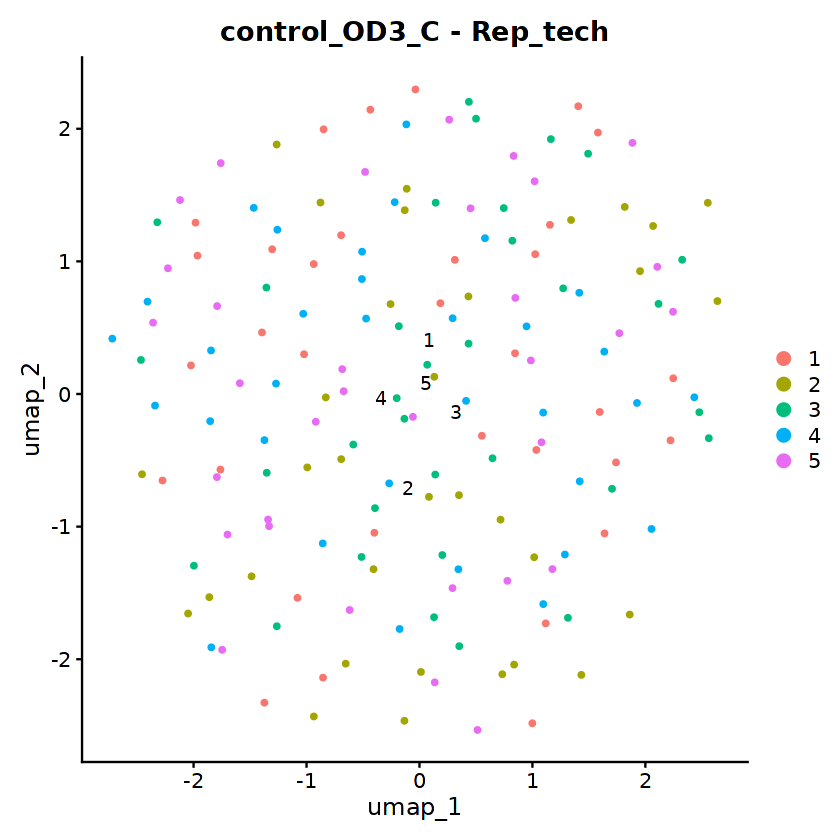

In [13]:
# plot for Stress_OD3_C
control_od3_c <- seurat_obj_list[["control_OD3_C"]]
p1 <- DimPlot(control_od3_c, label = TRUE, repel = TRUE, group.by = "Rep_tech") + ggtitle("control_OD3_C - Rep_tech")
print(p1)


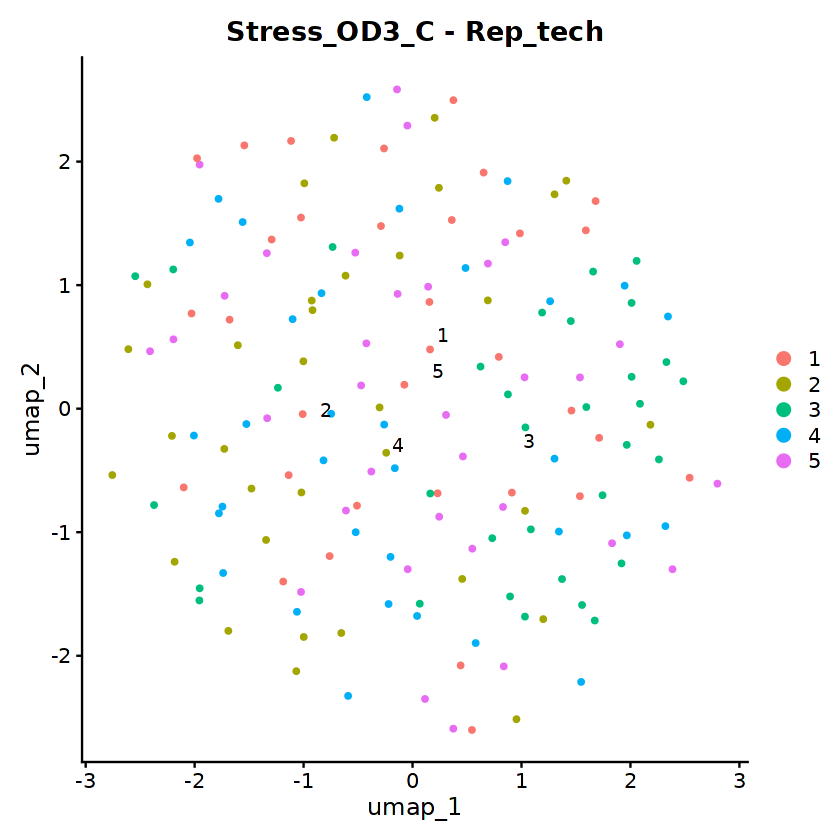

In [14]:
# plot for Stress_OD3_C
stress_od3_c <- seurat_obj_list[["stress_OD3_C"]]
p1 <- DimPlot(stress_od3_c, label = TRUE, repel = TRUE, group.by = "Rep_tech") + ggtitle("Stress_OD3_C - Rep_tech")
print(p1)


- avec GLM gamma Poisson on voit moins bien la distinction de ce cluster rep 3 : la methode est plius rapide ais je ne crois pas qu'elle soit adapté a nos données

- je décide de retirer tous de meme ce réplica 

In [15]:
# remove the bad replicate
seurat_obj_list_filtered <- seurat_obj_list
seurat_obj_list_filtered[["stress_OD3_C"]] <- subset(seurat_obj_list[["stress_OD3_C"]], subset = Rep_tech != "3")

# Check the number of cells after filtering
cell_counts_filtered <- sapply(seurat_obj_list_filtered, function(x) ncol(x))
# Display the cell counts after filtering
cat("\nNumber of cells in each object after filtering:\n")
print(cell_counts_filtered)


filtrer <- seurat_obj_list_filtered[["stress_OD3_C"]]
summary_stats_sample <- filtrer@meta.data %>%
    group_by(Sample_ID) %>%
    summarise(
        n_cells = n(),
        min_nCount_RNA = min(nCount_RNA, na.rm = TRUE),
        q1_nCount_RNA = quantile(nCount_RNA, 0.25, na.rm = TRUE),
        median_nCount_RNA = median(nCount_RNA, na.rm = TRUE),
        q3_nCount_RNA = quantile(nCount_RNA, 0.75, na.rm = TRUE),
        max_nCount_RNA = max(nCount_RNA, na.rm = TRUE),
        sd_nCount_RNA = sd(nCount_RNA, na.rm = TRUE),
        min_nFeature_RNA = min(nFeature_RNA, na.rm = TRUE),
        q1_nFeature_RNA = quantile(nFeature_RNA, 0.25, na.rm = TRUE),
        mean_nFeature_RNA = mean(nFeature_RNA, na.rm = TRUE),
        median_nFeature_RNA = median(nFeature_RNA, na.rm = TRUE),
        q3_nFeature_RNA = quantile(nFeature_RNA, 0.75, na.rm = TRUE),
        max_nFeature_RNA = max(nFeature_RNA, na.rm = TRUE),
        sd_nFeature_RNA = sd(nFeature_RNA, na.rm = TRUE)
    )

View(summary_stats_sample)



Number of cells in each object after filtering:
 stress_OD1_B control_OD1_B control_OD2_B  stress_OD2_A control_OD3_B 
          165           165           165           165           165 
 stress_OD3_C control_OD3_C control_OD1_C  stress_OD1_A control_OD2_C 
          132           165           165           165           165 
 stress_OD1_C control_OD2_A  stress_OD3_B  stress_OD2_C  stress_OD2_B 
          165           165           165           165           165 
control_OD3_A control_OD1_A  stress_OD3_A 
          165           165           165 


Sample_ID,n_cells,min_nCount_RNA,q1_nCount_RNA,median_nCount_RNA,q3_nCount_RNA,max_nCount_RNA,sd_nCount_RNA,min_nFeature_RNA,q1_nFeature_RNA,mean_nFeature_RNA,median_nFeature_RNA,q3_nFeature_RNA,max_nFeature_RNA,sd_nFeature_RNA
<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<dbl>,<dbl>,<int>,<dbl>,<int>,<dbl>
M9_C_1_OD3,33,208,237,248,284,588.0000,90.42092,128,140,170.7576,158,178,301,41.93077
M9_C_2_OD3,33,270,295,327,397,722.0000,102.35131,156,182,209.6061,201,233,356,44.23512
M9_C_4_OD3,33,197,232,267,328,604.9999,88.47669,129,148,178.0606,169,193,310,39.87867
M9_C_5_OD3,33,183,205,237,268,389.0000,51.02814,118,135,156.0606,151,168,235,28.08463


## remove on original data

In [16]:
summary_stats_sample <- seurat_obj@meta.data %>%
    group_by(Sample_ID) %>%
    summarise(
        n_cells = n(),
    ) |>
    tail((n <- 10))

View(summary_stats_sample)


Sample_ID,n_cells
<chr>,<int>
M9_C_2_OD3,33
M9_C_3_OD1,33
M9_C_3_OD2,33
M9_C_3_OD3,33
M9_C_4_OD1,33
M9_C_4_OD2,33
M9_C_4_OD3,33
M9_C_5_OD1,33
M9_C_5_OD2,33


In [17]:
# Filter by Sample - Remove specific sample
# The correct syntax is:
seurat_obj_f <- subset(seurat_obj, subset = Sample_ID != "M9_C_3_OD3")

# Summary statistics by Culture_medium for original object
summary_stats_sample <- seurat_obj@meta.data %>%
    group_by(Culture_medium) %>%
    summarise(
        n_cells = n(),
    )
print(summary_stats_sample)



# Summary statistics by Culture_medium for filtered object
summary_stats_sample_filtered <- seurat_obj_f@meta.data %>%
    group_by(Culture_medium) %>%
    summarise(
        n_cells = n(),
    )
print(summary_stats_sample_filtered)


# A tibble: 2 x 2
  Culture_medium n_cells
  <chr>            <int>
1 M9                1485
2 M9F               1485
# A tibble: 2 x 2
  Culture_medium n_cells
  <chr>            <int>
1 M9                1452
2 M9F               1485


le filtre a focntionné

# SEURAT classic workflow

## Check general aspect of the filtered object
cat("\nMetadata overview of the filtered object:\n")

In [34]:
seurat_object  <- seurat_obj_f

In [35]:
cat("Average overall counts per cell:", mean(seurat_object@meta.data$nCount_RNA), "\n")
cat("Average number of genes per cell:", mean(seurat_object@meta.data$nFeature_RNA), "\n")
cat("Median overall counts per cell:", median(seurat_object@meta.data$nCount_RNA), "\n")
cat("Median number of genes per cell:", median(seurat_object@meta.data$nFeature_RNA), "\n")


Average overall counts per cell: 776.7919 
Average number of genes per cell: 348.6142 
Median overall counts per cell: 540 
Median number of genes per cell: 285 


In [36]:
# Using dplyr to access and summarize the data
seurat_object@meta.data %>%
    summarise(
        mean_nCount_RNA = mean(nCount_RNA),
        mean_nFeature_RNA = mean(nFeature_RNA),
        median_nCount_RNA = median(nCount_RNA),
        median_nFeature_RNA = median(nFeature_RNA)
    ) 


mean_nCount_RNA,mean_nFeature_RNA,median_nCount_RNA,median_nFeature_RNA
<dbl>,<dbl>,<dbl>,<int>
776.7919,348.6142,540,285


In [37]:
# Using dplyr to access and summarize the data
seurat_object@meta.data  |> 
group_by(Sample_ID) %>%
    summarise(
        mean_nCount_RNA = mean(nCount_RNA),
        mean_nFeature_RNA = mean(nFeature_RNA),
        median_nCount_RNA = median(nCount_RNA),
        median_nFeature_RNA = median(nFeature_RNA)
    ) 


Sample_ID,mean_nCount_RNA,mean_nFeature_RNA,median_nCount_RNA,median_nFeature_RNA
<chr>,<dbl>,<dbl>,<dbl>,<int>
M9F_A_1_OD1,2049.4545,749.2424,1929.0000,732
M9F_A_1_OD2,528.0606,279.8182,478.9999,260
M9F_A_1_OD3,705.5151,343.0303,633.9999,326
M9F_A_2_OD1,908.1818,417.3333,817.0000,391
M9F_A_2_OD2,1576.6060,628.3333,1524.0001,614
M9F_A_2_OD3,245.7576,144.2424,225.0000,136
M9F_A_3_OD1,1117.1818,490.3030,1038.9999,463
M9F_A_3_OD2,398.7879,226.2424,370.9999,217
M9F_A_3_OD3,1578.4242,631.6364,1489.9999,611


In [38]:
# Using dplyr to access and summarize the data
seurat_object@meta.data  |> 
group_by(Condition_OD_timepoint_Rep_bio) %>%
    summarise(
        mean_nCount_RNA = mean(nCount_RNA),
        mean_nFeature_RNA = mean(nFeature_RNA),
        median_nCount_RNA = median(nCount_RNA),
        median_nFeature_RNA = median(nFeature_RNA)
    ) 

Condition_OD_timepoint_Rep_bio,mean_nCount_RNA,mean_nFeature_RNA,median_nCount_RNA,median_nFeature_RNA
<chr>,<dbl>,<dbl>,<dbl>,<dbl>
control_OD1_A,1468.2788,589.1455,1466.0000,604.0
control_OD1_B,2333.1333,809.4788,2162.0000,789.0
control_OD1_C,931.9151,421.7030,863.0000,403.0
control_OD2_A,822.4727,378.5333,636.0001,319.0
control_OD2_B,857.6606,396.4303,681.0001,356.0
control_OD2_C,894.8182,410.5333,779.0000,384.0
control_OD3_A,679.8788,316.1879,498.0000,268.0
control_OD3_B,659.5697,306.8182,439.0000,242.0
control_OD3_C,699.3939,333.7697,660.0000,328.0


In [39]:
# Using dplyr to access and summarize the data
seurat_object@meta.data  |> 
group_by(Condition_OD_timepoint) %>%
    summarise(
        mean_nCount_RNA = mean(nCount_RNA),
        mean_nFeature_RNA = mean(nFeature_RNA),
        median_nCount_RNA = median(nCount_RNA),
        median_nFeature_RNA = median(nFeature_RNA)
    ) 

Condition_OD_timepoint,mean_nCount_RNA,mean_nFeature_RNA,median_nCount_RNA,median_nFeature_RNA
<chr>,<dbl>,<dbl>,<dbl>,<dbl>
control_OD1,1577.7757,606.7758,1386.0000,575
control_OD2,858.3172,395.1657,722.0000,359
control_OD3,679.6141,318.9253,567.9999,288
stress_OD1,857.0848,384.5475,643.0000,323
stress_OD2,226.5212,140.9677,204.0000,130
stress_OD3,438.9134,237.9242,375.0000,218



dans notre exp : control OD1 


faire un tableau 
median de 1300 mRNA transcript par cell contre 325 
median de 500 genes (RNA) par cell contre 241 (jsp si c'est tout )



dans Probac-seq 

https://www.nature.com/articles/s41564-023-01348-4

ProBac-seq identifies heterogeneity in B. subtilis
We performed ProBac-seq on B. subtilis grown to late exponential phase in M9 minimal media supplemented with malate. In total, 2,784 cells were captured as determined by unique barcodes at an average depth of 1,073 reads per cell. We detected a median of 325 mRNA transcripts per cell (approximately 10–20% of the total mRNA pool4,17) corresponding to a median of 241 genes per cell. UMIs per probe ranged from 0 to 45 for any given gene in any given cell. The most highly detected probes targeted genes encoding ribosomal proteins (rpsG, rpsH, rpsR, rpsM, rpsS, rplL, rplD, rplO, rplV), translation elongation machinery (fusA, tufA, map) and transcriptional machinery (rpoA).

## Normalize the data

After removing unwanted cells from the dataset, the next step is to normalize the data. By default, Seurat employs a global-scaling normalization method “LogNormalize” that normalizes the feature expression measurements for each cell by the total expression, multiplies this by a scale factor, and log-transforms the result. The scale factor by default is set to 10,000. 


In [40]:
#seurat_object <- NormalizeData(seurat_object, normalization.method = "LogNormalize", scale.factor = 10000)

seurat_object <- NormalizeData(seurat_object, normalization.method = "LogNormalize", scale.factor = 1000)

Normalizing layer: counts



## Identification of highly variable features (feature selection)


You next need to identify a subset of features that exhibit high cell-to-cell variation in the dataset (i.e, they are highly expressed in some cells, and lowly expressed in other cells). You will normally find that focusing on these genes in downstream analysis helps to highlight biological signal in single-cell datasets, and help reduce computational and statistical impacts of analysing who genomes worth of genes in a zero-inflated count matrix! 

We can do this by implementing the `FindVariableFeatures()` function. Use the below function to find the top 2000 variable features in the dataset. 


In [41]:
seurat_object <- FindVariableFeatures(seurat_object, selection.method = "vst", nfeatures = 1000)

Finding variable features for layer counts



Using head(), you can show the top 10 variable features in your dataset, and assign this to a variable called top10. You can change the value of `n` to show however many features you would like to inspect.

In [42]:
# Exploring variable features
top10 <- head(VariableFeatures(seurat_object), n=10)
top10

[1] "QLH64-16410" "QLH64-23490" "QLH64-25115" "QLH64-12320" "QLH64-24590"
 [6] "QLH64-08635" "QLH64-22445" "QLH64-28020" "QLH64-19950" "fabF"

You can now plot the highly variable genes by plotting the average expression against the standised variance. The top 2000 most variable genes will be highlighted in Red while the rest will be black. The number of genes in each category is displayed next to the label on the legend.

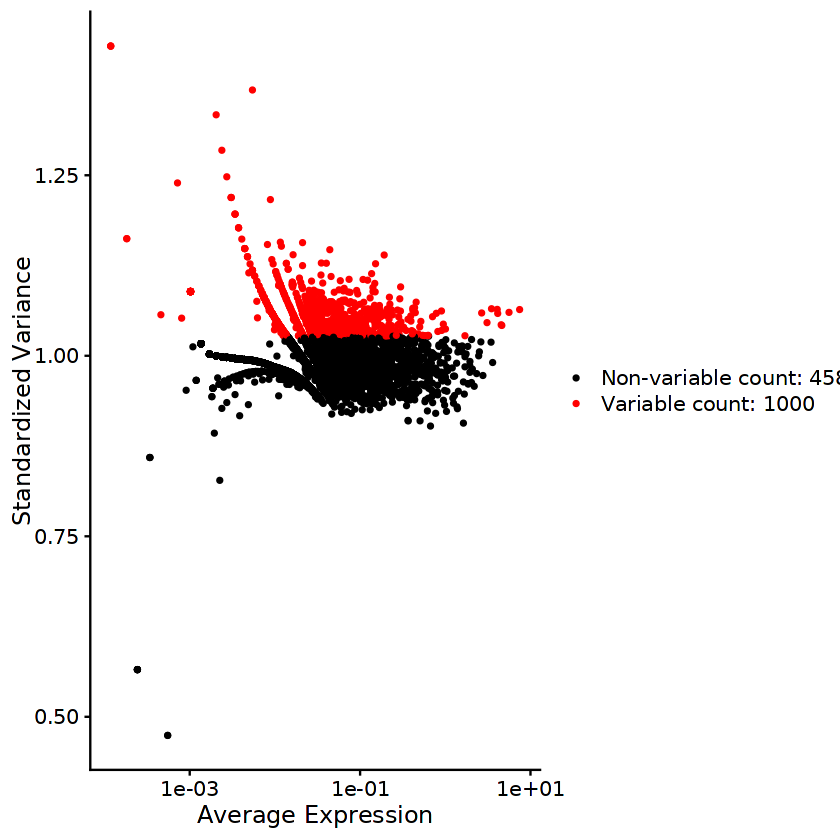

In [43]:
var_feat_plot <- VariableFeaturePlot(seurat_object)
var_feat_plot

To go one step further, you can label the top 10 genes you already pulled out of the dataset. By adding data labels you can easily see these genes. Seurat has a helpher function to produce this plot called `LabelPoints` which we can use alongside the top 10 genes list to label them on the plot.**

When using repel, set xnudge and ynudge to 0 for optimal results



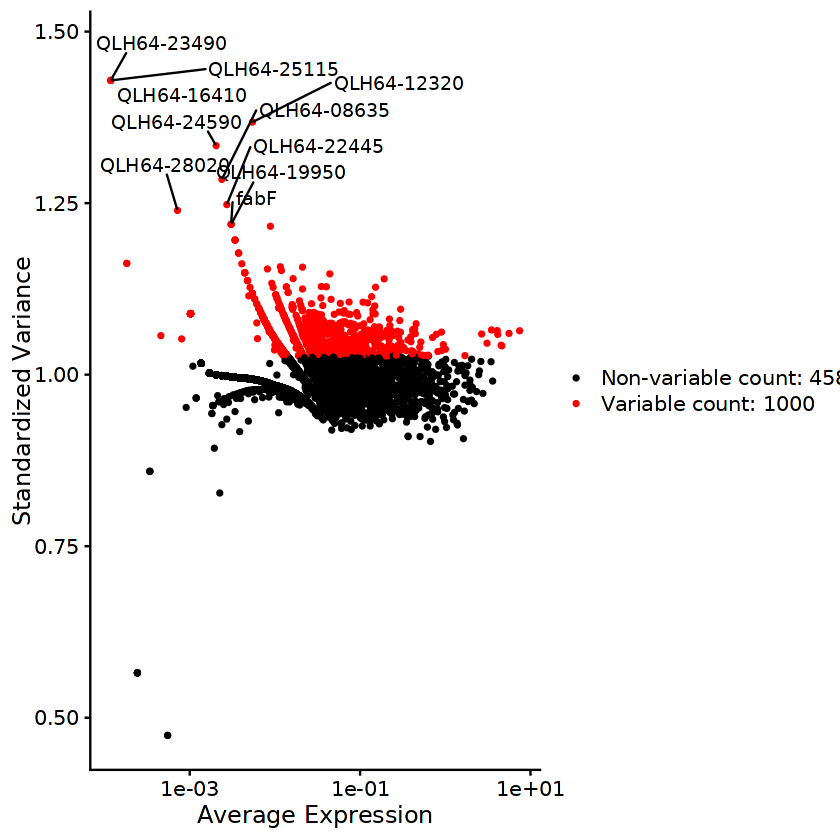

In [44]:
var_feat_plot_labeled <- LabelPoints(plot = var_feat_plot, points = top10, repel = TRUE)
var_feat_plot_labeled

## Step 7: Scaling 

Next, you apply a linear transformation (‘scaling’) that is a standard pre-processing step prior to dimensional reduction techniques like PCA. The `ScaleData()` function:

- Shifts the expression of each gene, so that the mean expression across cells is 0
- Scales the expression of each gene, so that the variance across cells is 1

This step gives equal weight in downstream analyses, so that the most highly-expressed genes do not dominate the rest of the analysis.

* **Tip**: the results of this are stored in seurat_object[["RNA"]]@scale.data*

(This might take a little while, don't panic!)

In [45]:
all_genes <- rownames(seurat_object)
seurat_object <- ScaleData(seurat_object, features = all_genes)

Centering and scaling data matrix



## Step 8: PCA 


Next you perform PCA on the scaled data. This is the first stage in dimensionality reduction - lowering the dimensional complexity of our gene data to be able to make inferences about our data. By default, only the previously determined highly variable features are used as input (here we are going forward with only the top 2000 most variable genes).

Run PCA on your Seurat object using the below command. This might print out a large log of gene names - don't worry, that means it has worked!


In [46]:
seurat_object <- RunPCA(seurat_object, features = VariableFeatures(object = seurat_object))

PC_ 1 
Positive:  QLH64-19225, fusA, QLH64-02935, QLH64-26960, rpoC, QLH64-13720, QLH64-05400, icd, QLH64-13705, QLH64-13710 
	   QLH64-07480, ppsA, QLH64-30060, QLH64-27525, rplL, QLH64-19800, QLH64-31045, gltA, secA, QLH64-04320 
	   QLH64-12130, QLH64-12185, QLH64-13080, sdhA, QLH64-24685, gltB, tcyJ, QLH64-18250, QLH64-13345, QLH64-02960 
Negative:  QLH64-24105, QLH64-27715, QLH64-20710, QLH64-25105, QLH64-19625, QLH64-26985, QLH64-02630, tusB, QLH64-19510, QLH64-24600 
	   QLH64-17150, QLH64-21740, QLH64-20920, QLH64-10225, pnuC, choX, QLH64-08015, QLH64-19620, QLH64-13100, QLH64-07645 
	   QLH64-01675, hutU, QLH64-15350, QLH64-01420, QLH64-14500, QLH64-13500, QLH64-28020, QLH64-06780, QLH64-28240, QLH64-14680 
PC_ 2 
Positive:  QLH64-26220, QLH64-22950, QLH64-16885, rpsJ, QLH64-25585, QLH64-13345, hemE, QLH64-15375, QLH64-24320, QLH64-14565 
	   QLH64-17815, QLH64-21555, QLH64-01920, QLH64-16030, QLH64-30905, QLH64-09265, topA, QLH64-22145, QLH64-09340, QLH64-30870 
	   rlmN, QLH

Now if you inspect your Seurat object again you can see that you have `1 dimensional reduction calculated:`. This means that you have added the results from your PCA reduction to the Seurat object.

In [47]:
seurat_object

An object of class Seurat 
5584 features across 2937 samples within 1 assay 
Active assay: RNA (5584 features, 1000 variable features)
 3 layers present: counts, data, scale.data
 1 dimensional reduction calculated: pca

You can see the first n features in x: y of your PCA using. i.e. `seurat_object[["pca"]], dims = x:y, nfeatures = n)`. This command will show the top n features that are both positively and negatives contributing to the reduction.

In [48]:
print(seurat_object[["pca"]], dims = 1:15, nfeatures = 10)

PC_ 1 
Positive:  QLH64-19225, fusA, QLH64-02935, QLH64-26960, rpoC, QLH64-13720, QLH64-05400, icd, QLH64-13705, QLH64-13710 
Negative:  QLH64-24105, QLH64-27715, QLH64-20710, QLH64-25105, QLH64-19625, QLH64-26985, QLH64-02630, tusB, QLH64-19510, QLH64-24600 
PC_ 2 
Positive:  QLH64-26220, QLH64-22950, QLH64-16885, rpsJ, QLH64-25585, QLH64-13345, hemE, QLH64-15375, QLH64-24320, QLH64-14565 
Negative:  QLH64-19010, QLH64-22455, QLH64-07335, QLH64-08810, QLH64-12160, treS, fabB, QLH64-02870, guaD, flgE 
PC_ 3 
Positive:  QLH64-04080, QLH64-19920, icd, QLH64-25445, ccoG, QLH64-24695, QLH64-13355, pyrC, QLH64-19990, QLH64-13945 
Negative:  QLH64-00535, QLH64-25595, ppc, QLH64-13350, QLH64-29030, QLH64-18305, panB, truB, QLH64-22380, QLH64-30375 
PC_ 4 
Positive:  hisD, QLH64-04295, pap, QLH64-18790, QLH64-22200, QLH64-30485, QLH64-29075, QLH64-19860, QLH64-29080, gguC 
Negative:  QLH64-25830, QLH64-06520, QLH64-00395, nagZ, QLH64-23660, QLH64-19035, QLH64-03650, QLH64-20870, QLH64-19720, Q


Feel free to play around with different PCs this might come in handy later on in your analysis!

## Explore and visualise the PCA results a few different ways

Seurat provides several useful ways of visualizing both cells and features that define the PCA, including `VizDimReduction()`, `DimPlot()`, and `DimHeatmap()`

### Using VizDimLoadings()
You can visualise the top genes associated with each principle reduction components e.g. for the first 2 components using `VizDimReduction()`.

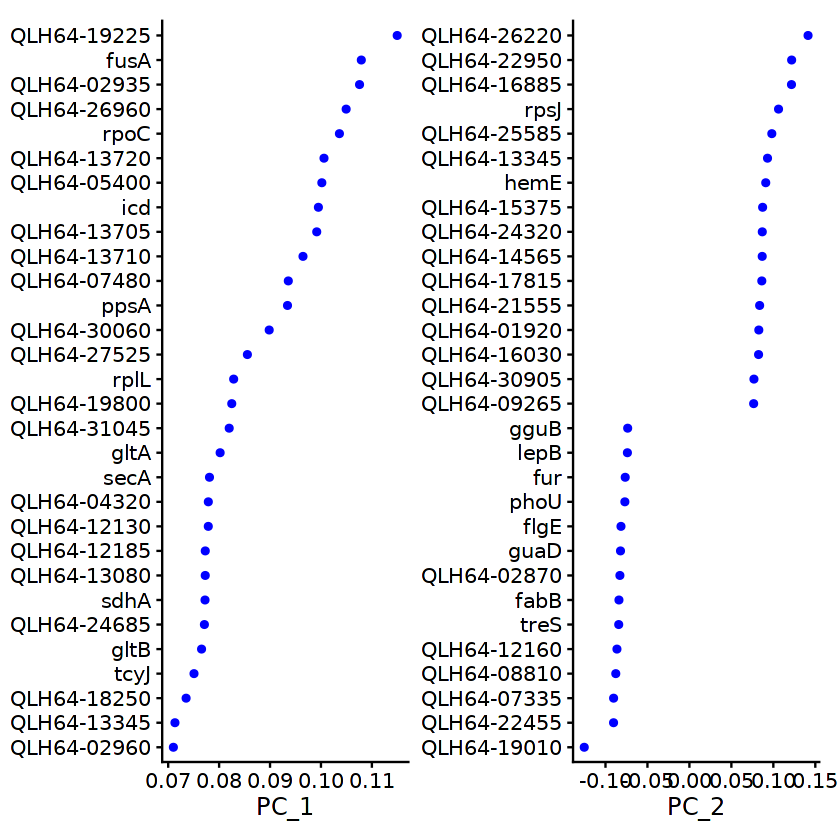

In [49]:
VizDimLoadings(seurat_object, dims = 1:2)

Or alternatively by adding some additional parameters, you can view the first 6 components and their top 10 genes. The larger the loading (i.e. the more positive) the greater the variance and therefore the effect that gene has on that component.

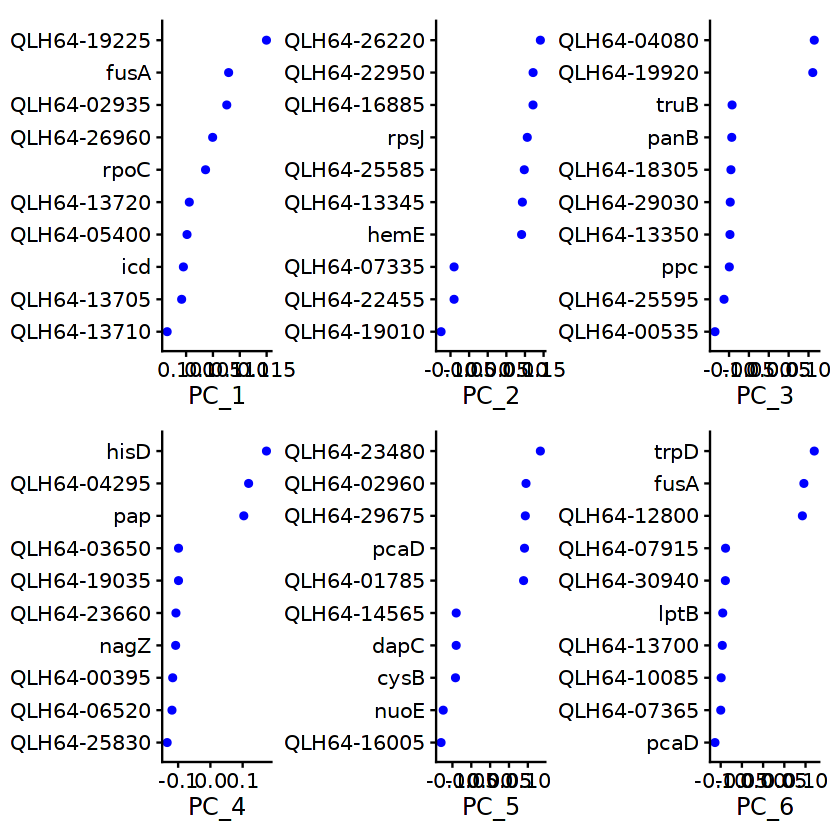

In [50]:
VizDimLoadings(seurat_object, dims = 1:6, reduction = "pca", ncol = 3, nfeature=10)

## Using DimPlot()

Another way to visualise the dimensional reduction produced by the PCA is to plot the components on a 2D scatterplot where each point is a cell and it's position is based on the cell embeddings determined by the reduction technique. By default, cells are colored by their identity class (can be changed with the `group.by` parameter if you have the relevant data in the your `meta.data`).

Here is an example for the first 2 components:

Warning message:
"ggrepel: 18 unlabeled data points (too many overlaps). Consider increasing max.overlaps"


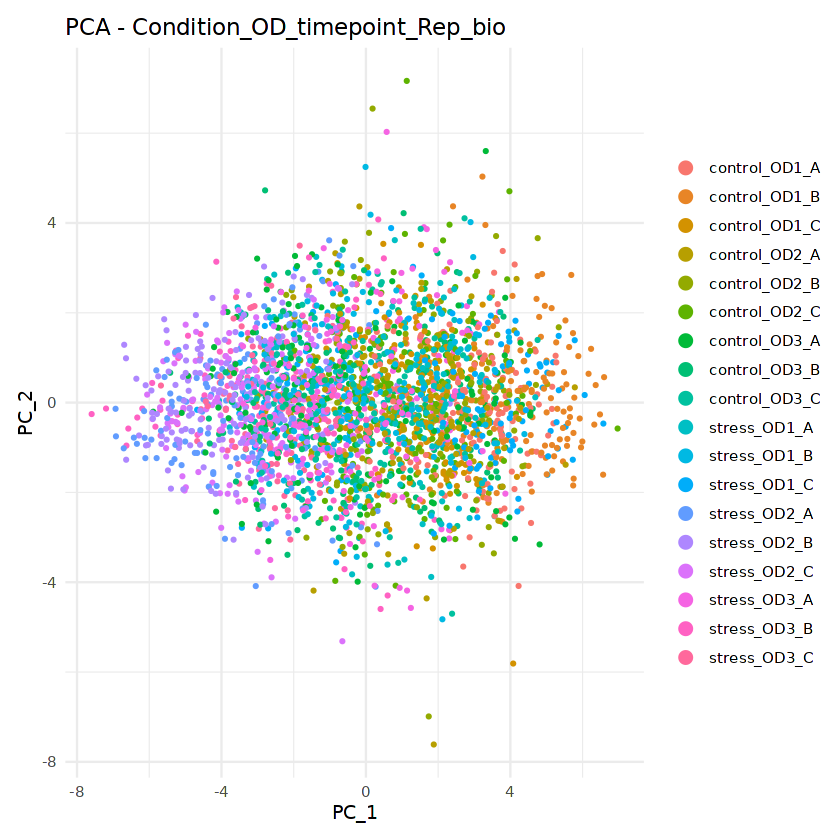

In [51]:
DimPlot(seurat_object, reduction = "pca", dims = 1:2, group.by = "Condition_OD_timepoint_Rep_bio", label = TRUE, repel = TRUE) +
    ggtitle("PCA - Condition_OD_timepoint_Rep_bio") +
    theme_minimal()

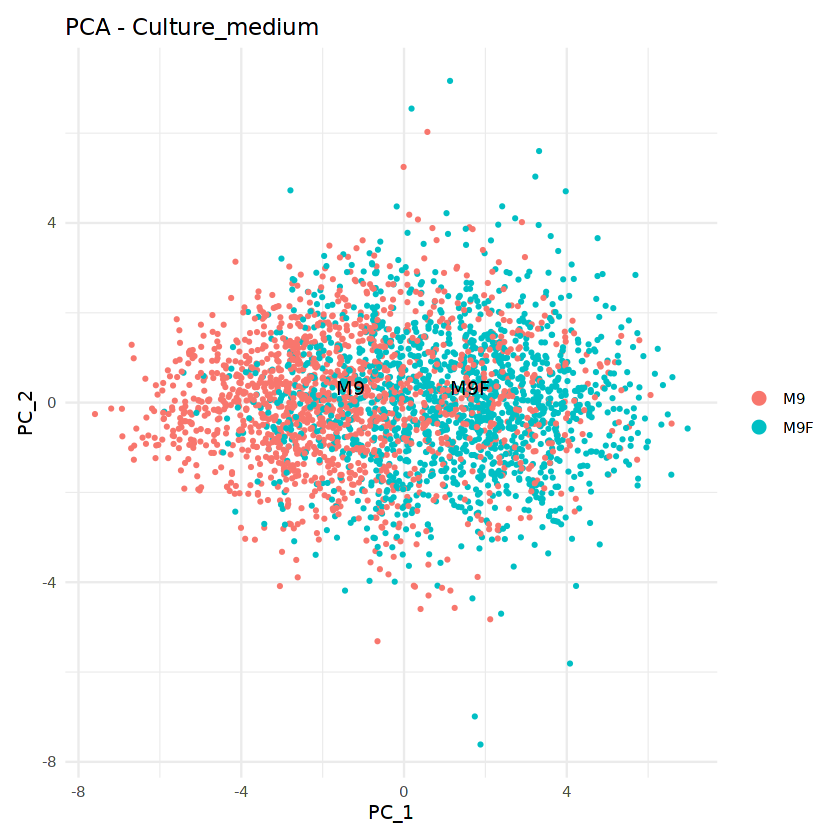

In [52]:
DimPlot(seurat_object, reduction = "pca", dims = 1:2, group.by = "Culture_medium", label = TRUE, repel = TRUE) +
    ggtitle("PCA - Culture_medium") +
    theme_minimal()

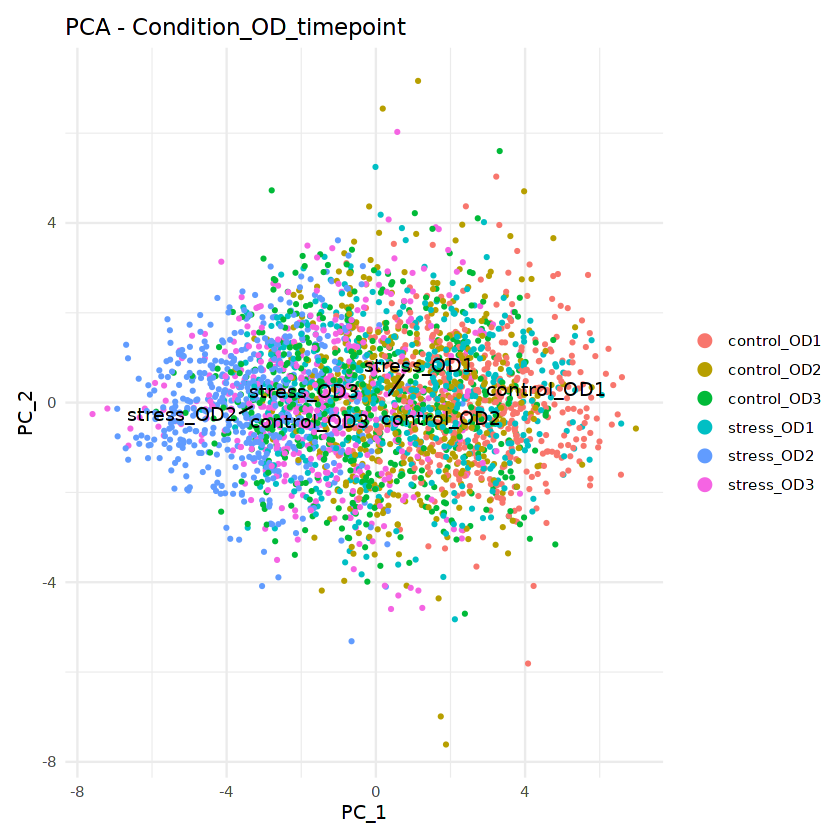

In [53]:
DimPlot(seurat_object, reduction = "pca", dims = 1:2, group.by = "Condition_OD_timepoint", label = TRUE, repel = TRUE) +
    ggtitle("PCA - Condition_OD_timepoint") +
    theme_minimal()

## Using DimHeatmap()

Draws a heatmap focusing on a principal component. Both cells and genes are sorted by their principal component scores. Allows for nice visualization of sources of heterogeneity in the dataset.

e.g. for PC 1, and how to show multiple heatmaps on the same plot.

**Question:** Trying investigation different dimensions by change the number after the `dim =` parameter

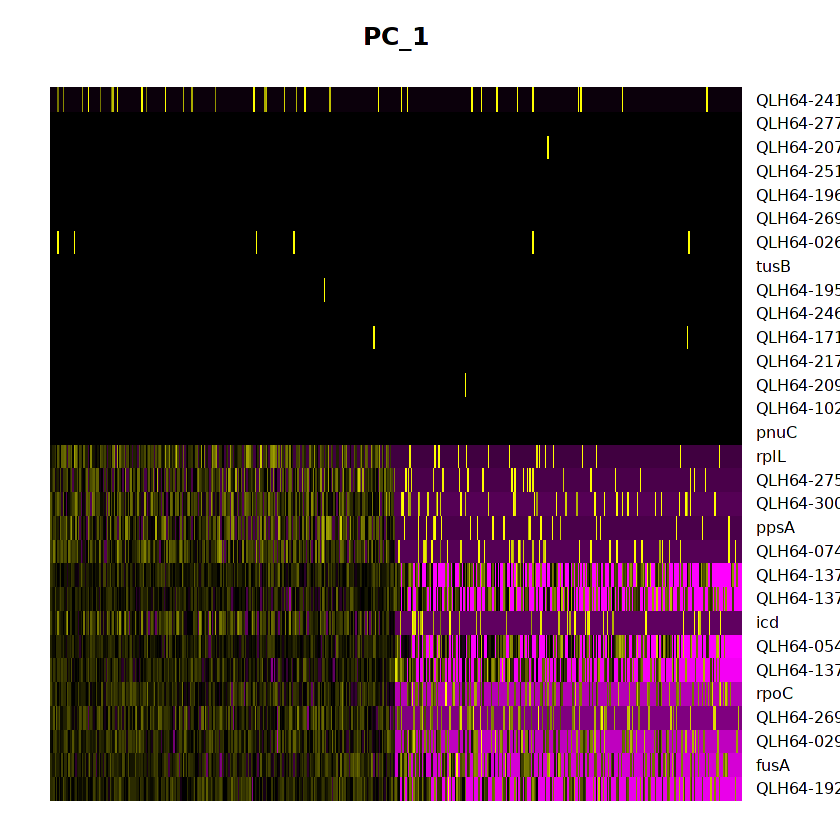

In [54]:


DimHeatmap(seurat_object, dims = 1, cells = 500, balanced = TRUE)

You can also plot multiple componets heatmaps in one plot.

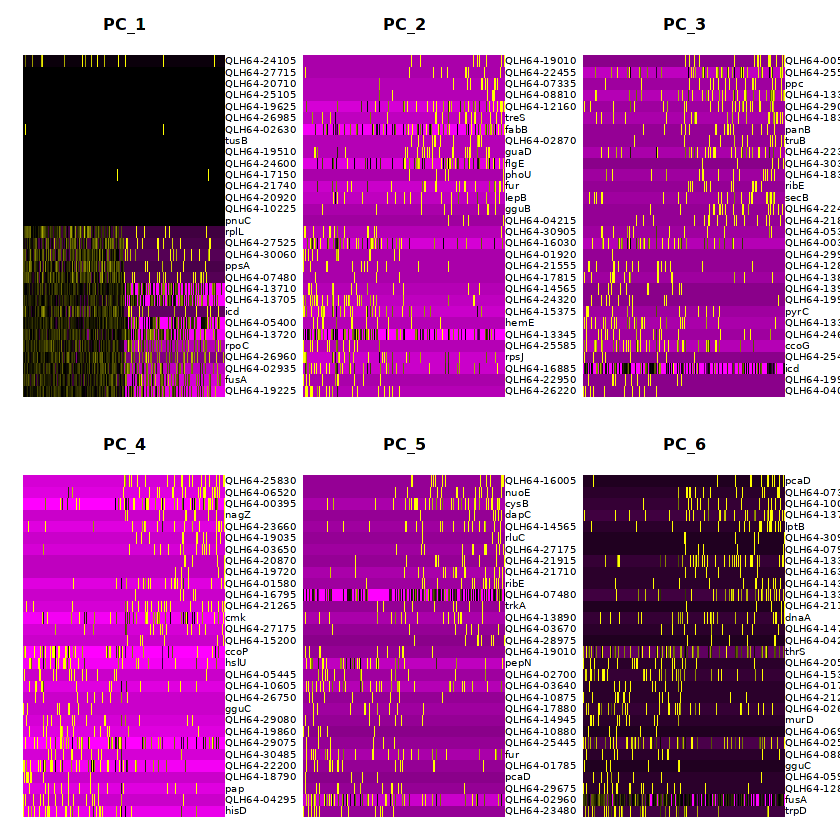

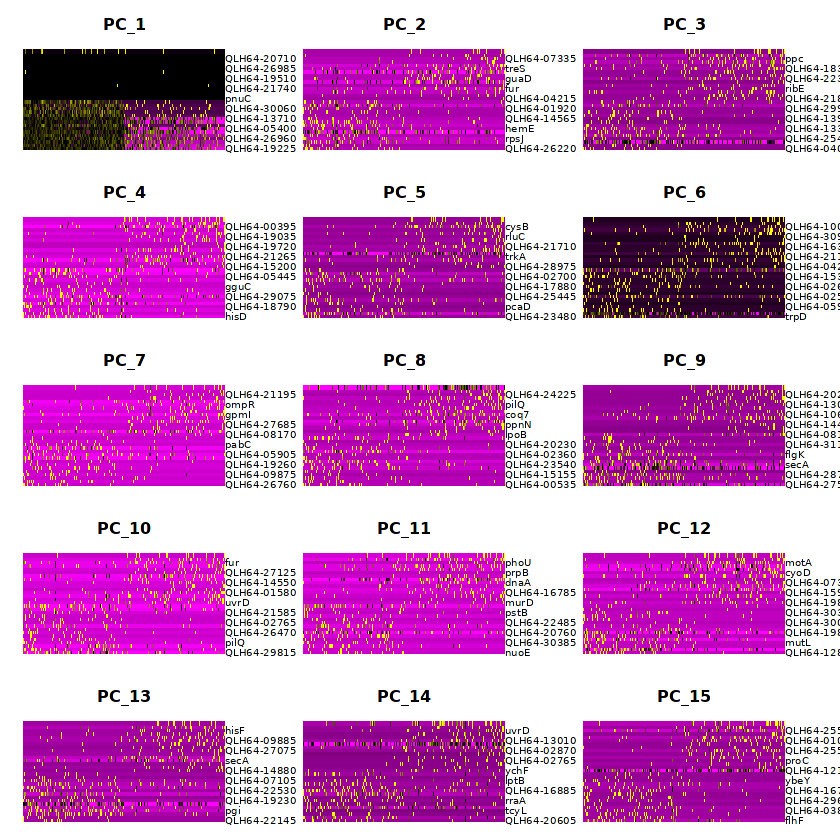

In [55]:
DimHeatmap(seurat_object, dims = 1:6, cells = 500, balanced = TRUE, ncol = 3)
DimHeatmap(seurat_object, dims = 1:15, cells = 500, balanced = TRUE, ncol = 3)

To overcome the extensive technical noise in any single feature for scRNA-seq data, Seurat clusters cells based on their PCA scores, with each PC essentially representing a ‘metafeature’ that combines information across a correlated feature set. The top principal components therefore represent a robust compression of the dataset. However, how many components should you choose to include? 10? 20? 100?

To help determine this you can use an 'Elbow Plot', a method of ranking of principle components based on the percentage of variance explained by each PC. To generate the plot you can use the function: `ElbowPlot()`

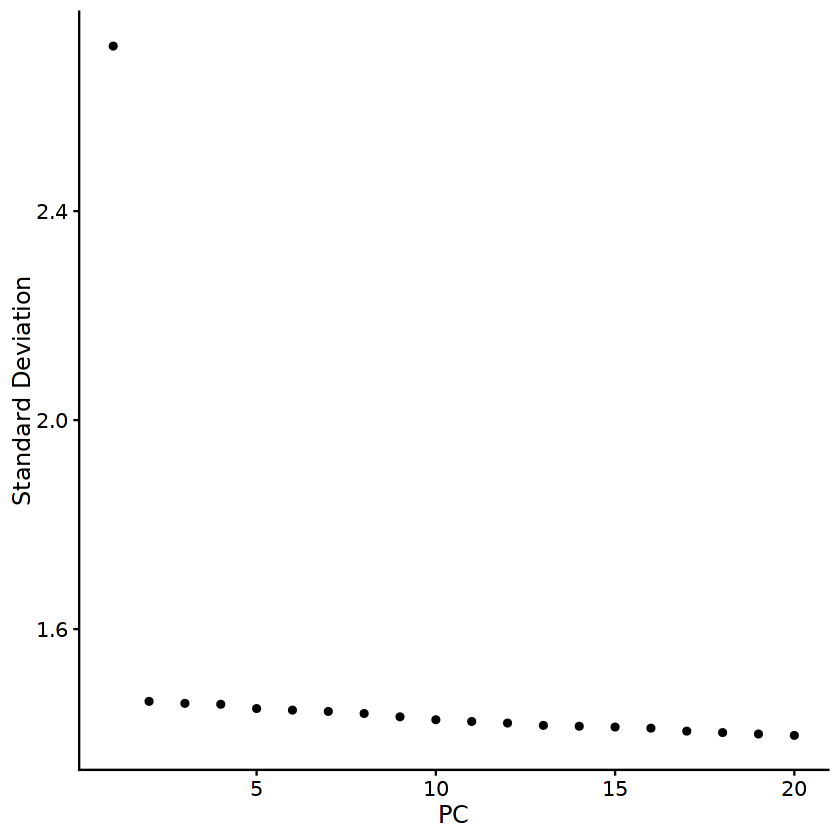

In [56]:
ElbowPlot(seurat_object)

**Question:** In your plot you should observe an 'elbow' where the curve plateaus, a PC from which there is little change in standard deviation and so including them wouldn't reveal much more about the dataset. From the results of your elbow plot, how many PCs are you going to use for your clustering and why?


## Clustering

Seurat applies a graph-based clustering approach, a method whereby cells are embedded in a graph structure with edges drawn between cells with similar feature expression patterns, and then attempts to partition this graph into highly interconnected ‘communities’. To cluster the cells (grouping cells together) we use the `FindClusters()` function.

### (1) Find Neighbours

First you construct a WNN (weighted nearest neighbours) graph based on the distance in PCA space, and refine the edge 'weights' between any two cells based on the shared overlap in their local neighborhoods. This step is performed using the `FindNeighbors()` function, and takes as input the previously defined dimensionality of the dataset (e.g. first 10 PCs).

**This is where your principal component analysis is important!**

**To do:** Using your results from the PCA section set the number of dimensions for the `FindNeighbours()` function to use:


In [57]:
#seurat_object <- FindNeighbors(seurat_object, dims = 1:10)
#seurat_object <- FindNeighbors(seurat_object, dims = 1:2)
seurat_object <- FindNeighbors(seurat_object, dims = 1:3)

Computing nearest neighbor graph



Computing SNN



### (2) Find Clusters

This function contains a parameter called resolution which sets the ‘granularity’ of the clustering.

* **Tip**: For the purposes of this project and dataset, I'd recommend using a resolution between 0.5-1. Feel free to play after with this parameter.*


In clustering analysis, resolution is a parameter that controls the granularity of clustering, meaning how finely or coarsely the data is partitioned into clusters.

How It Works:
	•	A lower resolution (e.g., 0.5) results in fewer, larger clusters, meaning that more data points are grouped together.
	•	A higher resolution (e.g., 1.0 or above) produces more, smaller clusters, meaning that finer distinctions are made between groups of data points.

In the Context of This Project:
	•	The resolution parameter is particularly relevant in graph-based clustering algorithms, such as Louvain or Leiden (commonly used in single-cell RNA-seq analysis with Seurat in R or Scanpy in Python).
	•	It determines how many clusters the algorithm will identify:
	•	Low resolution (0.5): Broad groupings, fewer clusters.
	•	High resolution (1.0): More subdivisions, capturing subtle differences.

Why Play with Resolution?
	•	The “best” resolution depends on the dataset and biological question.
	•	A resolution between 0.5 and 1 is a reasonable starting point, balancing granularity and interpretability.
	•	You can test different values to see which produces clusters that best reflect the expected biological structures in your data.

In [58]:
seurat_object <- FindClusters(seurat_object, resolution = 0.5)

Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 2937
Number of edges: 76353

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.8137
Number of communities: 8
Elapsed time: 0 seconds


**To do:** Look at cluster IDs of the first 5 cells eg. `head(Idents(object), x)`

Running this command will display the first 10 cells in your data with their newly assigned clusters (currently represented as numbers) that the louvain algorithm has decided the cell belongs too. Across the top will be the cell (either the barcode or the read name) and below it will be the cluster it is assigned to. At the very bottom you will see `Levels:...` this shows an overview of all the clusters found in the dataset.

In [59]:
head(Idents(seurat_object), 10)

GTACGCAA_AACCGAGA_AAACGATA CGGATTGC_AACGCTTA_AAACGATA 
                         3                          4 
CGCTGATC_AACGTGAT_AAACGATA GCTAACGA_AAGAGATC_AAACGATA 
                         4                          0 
CCTCTATC_AAGGACAC_AAACGATA GTGTTCTA_ACACAGAA_AAACGATA 
                         7                          2 
ACAGATTC_ACAGATTC_AAACGATA CAAGACTA_ACATTGGC_AAACGATA 
                         4                          5 
CCGTGAGA_ACCACTGT_AAACGATA ACTATGCA_AGTACAAG_AAACGATA 
                         3                          5 
Levels: 0 1 2 3 4 5 6 7


**Question:** Try running `FindClusters()` at different resolutions by changing the value of `resolution`, how does changing the resolution affect the function?

In [60]:
seurat_object <- FindClusters(seurat_object, resolution = 0.9)

Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 2937
Number of edges: 76353

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.7740
Number of communities: 13
Elapsed time: 0 seconds


In [61]:
head(Idents(seurat_object), 10)

GTACGCAA_AACCGAGA_AAACGATA CGGATTGC_AACGCTTA_AAACGATA 
                         3                          8 
CGCTGATC_AACGTGAT_AAACGATA GCTAACGA_AAGAGATC_AAACGATA 
                         5                          7 
CCTCTATC_AAGGACAC_AAACGATA GTGTTCTA_ACACAGAA_AAACGATA 
                         3                          9 
ACAGATTC_ACAGATTC_AAACGATA CAAGACTA_ACATTGGC_AAACGATA 
                         8                          4 
CCGTGAGA_ACCACTGT_AAACGATA ACTATGCA_AGTACAAG_AAACGATA 
                         3                          4 
Levels: 0 1 2 3 4 5 6 7 8 9 10 11 12

### (3) Run non-linear dimensional reduction (UMAP)

Seurat offers several non-linear dimensional reduction techniques, such as tSNE or in our case **UMAP**, to visualize and explore these datasets. The goal of these algorithms is to learn the underlying 'manifold' of the data in order to place similar cells together in low-dimensional space. Cells within the graph-based clusters determined above should co-localize on these dimension reduction plots.

* **Tip**: As input to the UMAP use the same number of PCs as input to the clustering analysis i.e. during FindNeighbors()*

In [62]:
#seurat_object <- RunUMAP(seurat_object, 1:10)
#seurat_object <- RunUMAP(seurat_object, 1:2)
seurat_object <- RunUMAP(seurat_object, 1:3)

14:54:46 UMAP embedding parameters a = 0.9922 b = 1.112

14:54:46 Read 2937 rows and found 3 numeric columns



14:54:46 Using Annoy for neighbor search, n_neighbors = 30

14:54:46 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

14:54:47 Writing NN index file to temp file /tmp/RtmpU6GDoF/file42f02bb743c5

14:54:47 Searching Annoy index using 1 thread, search_k = 3000

14:54:48 Annoy recall = 100%

14:54:51 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 30

14:54:57 Initializing from normalized Laplacian + noise (using RSpectra)

14:54:58 Commencing optimization for 500 epochs, with 85720 positive edges

14:54:58 Using rng type: pcg

14:55:02 Optimization finished



You can visualize this with DimPlot the same as PCA, but now you define the reduction to plot like this: 

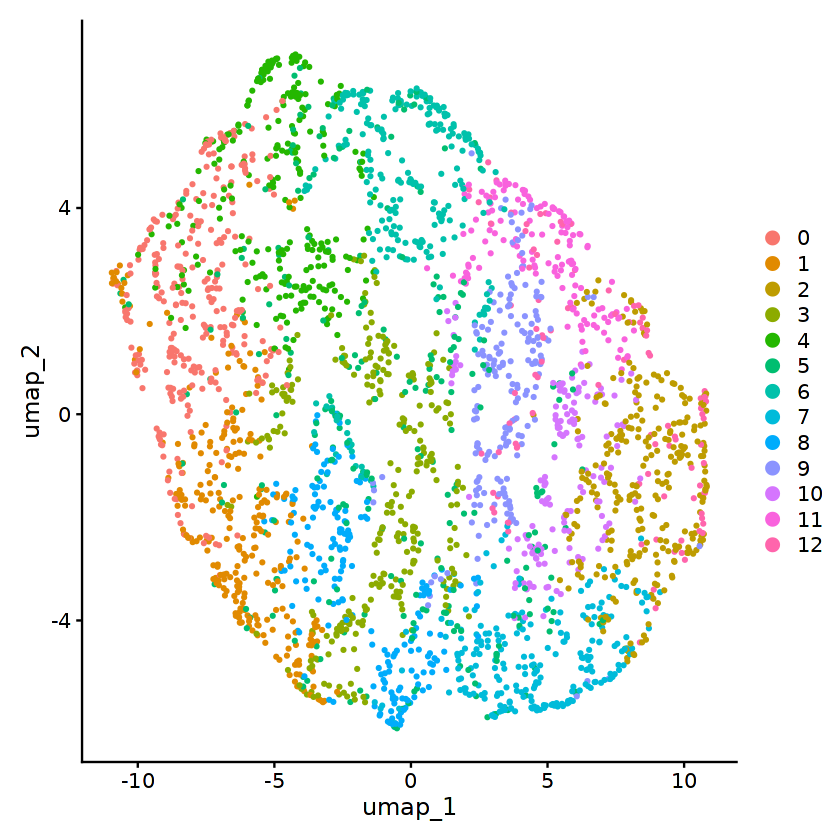

In [63]:
DimPlot(seurat_object, reduction = "umap")

**To do:** Now that you can visualize your UMAP clusters, go back to where you ran `FindNeighbours()` and have a go again with a lower or higher resolution (keeping dims the same). You should see how the resolution affects the function more clearly.

**Question**: This is really important. What do you think would be impact to the conclusions you may draw from your experiment of using a resolution that is too low?

* **Tip**: If you want to explore different ways of showing this data, remember to use `?DimPlot` to see which things you can modify. E.g. you can change the colour scheme, the point size, the factor to colour the points by etc!*

Here is the same UMAP coloured instead by the cell phenotypes. In this case we only have one item in the `meta.data` which we can plot. So we just display what project the data is from.

In [64]:
# Display available columns
cat("\nAvailable columns in metadata:\n")
colnames(seurat_obj@meta.data)


Available columns in metadata:


[1] "nCount_RNA"                     "nFeature_RNA"                  
 [3] "barcode.rd1"                    "barcode.rd2"                   
 [5] "barcode.rd3"                    "Well_loc_rd1"                  
 [7] "Well_loc_rd2"                   "Well_loc_rd3"                  
 [9] "Sample_ID"                      "Culture_medium"                
[11] "Rep_bio"                        "Rep_tech"                      
[13] "OD_timepoint"                   "OD_theoric"                    
[15] "OD_measured"                    "Condition"                     
[17] "Condition_OD_timepoint"         "Rep"                           
[19] "Condition_OD_timepoint_Rep_bio"

Warning message:
"ggrepel: 1 unlabeled data points (too many overlaps). Consider increasing max.overlaps"


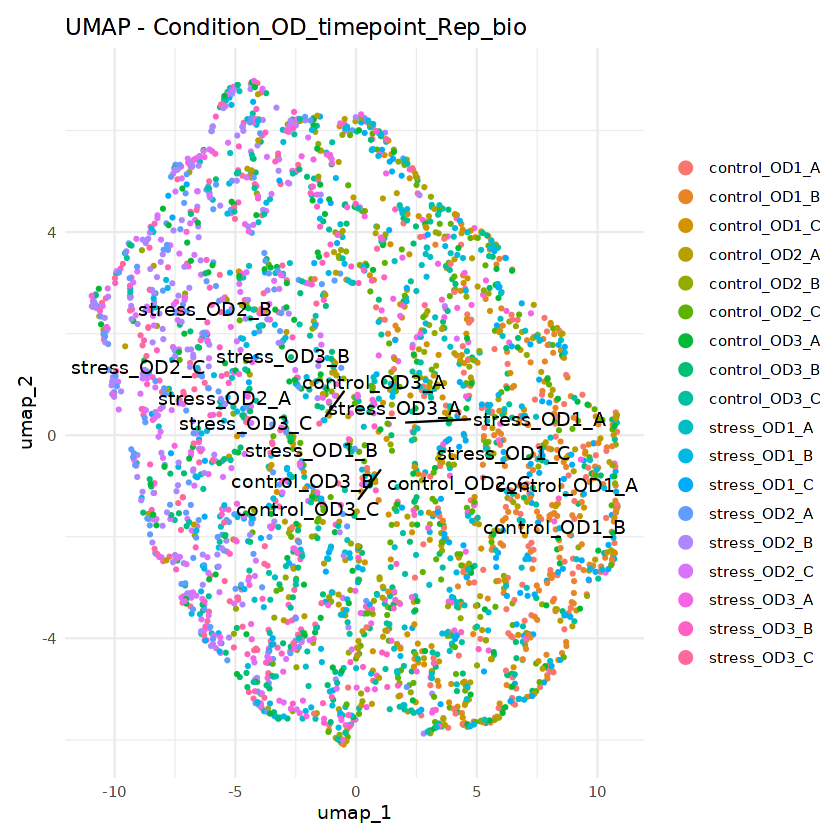

In [65]:
DimPlot(seurat_object, reduction = "umap", group.by = "Condition_OD_timepoint_Rep_bio", label = TRUE, repel = TRUE) +
    ggtitle("UMAP - Condition_OD_timepoint_Rep_bio") +
    theme_minimal()

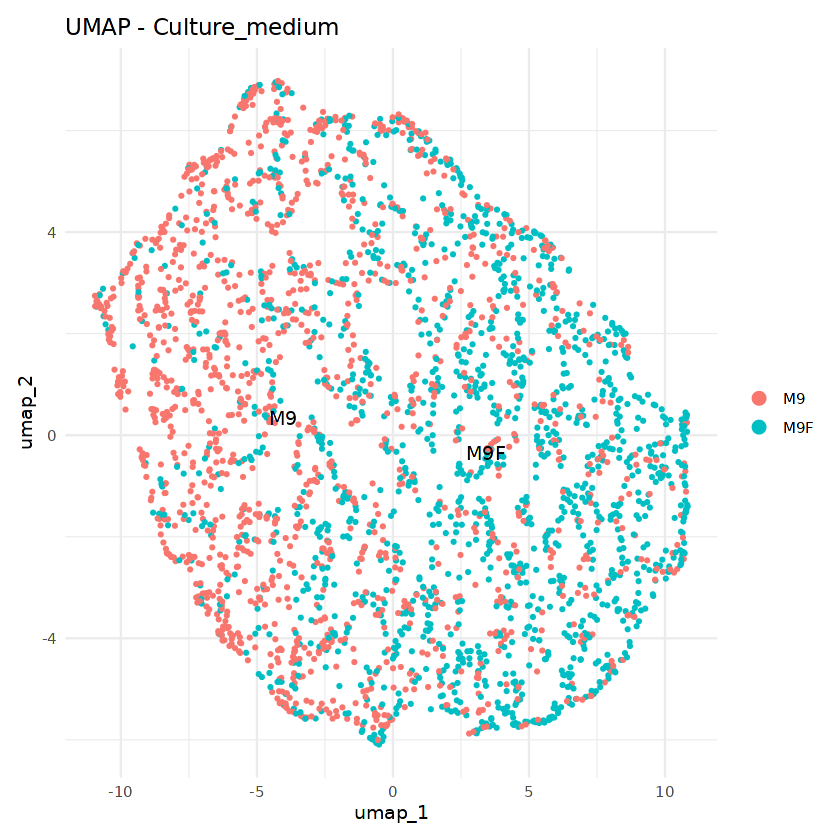

In [66]:
DimPlot(seurat_object, reduction = "umap", group.by = "Culture_medium", label = TRUE, repel = TRUE) +
    ggtitle("UMAP - Culture_medium") +
    theme_minimal()

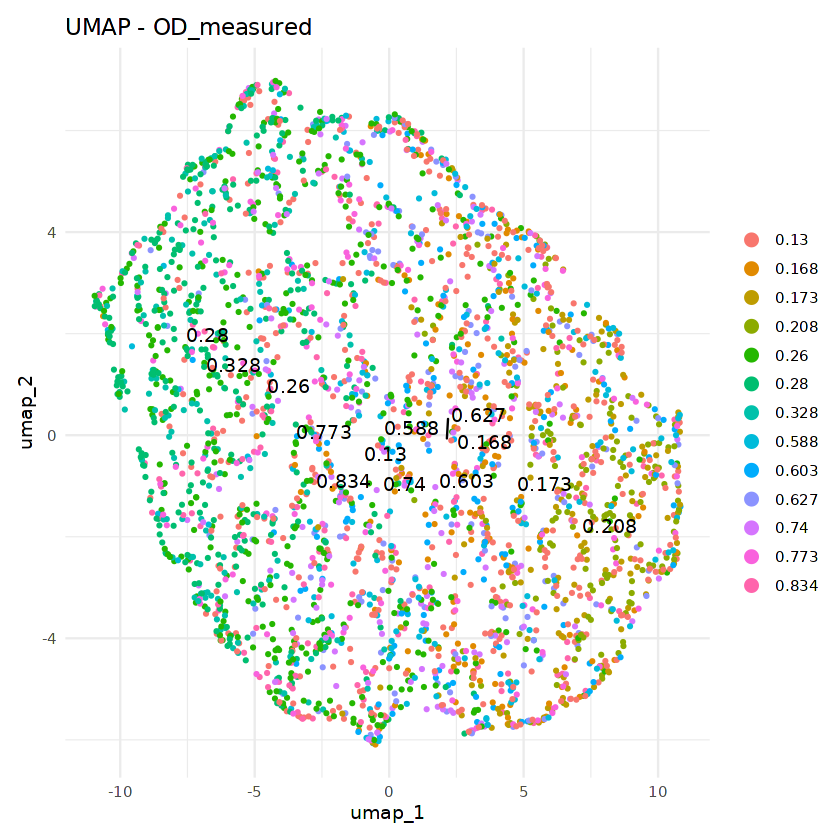

In [67]:
DimPlot(seurat_object, reduction = "umap", group.by = "OD_measured", label = TRUE, repel = TRUE) +
    ggtitle("UMAP - OD_measured") +
    theme_minimal()

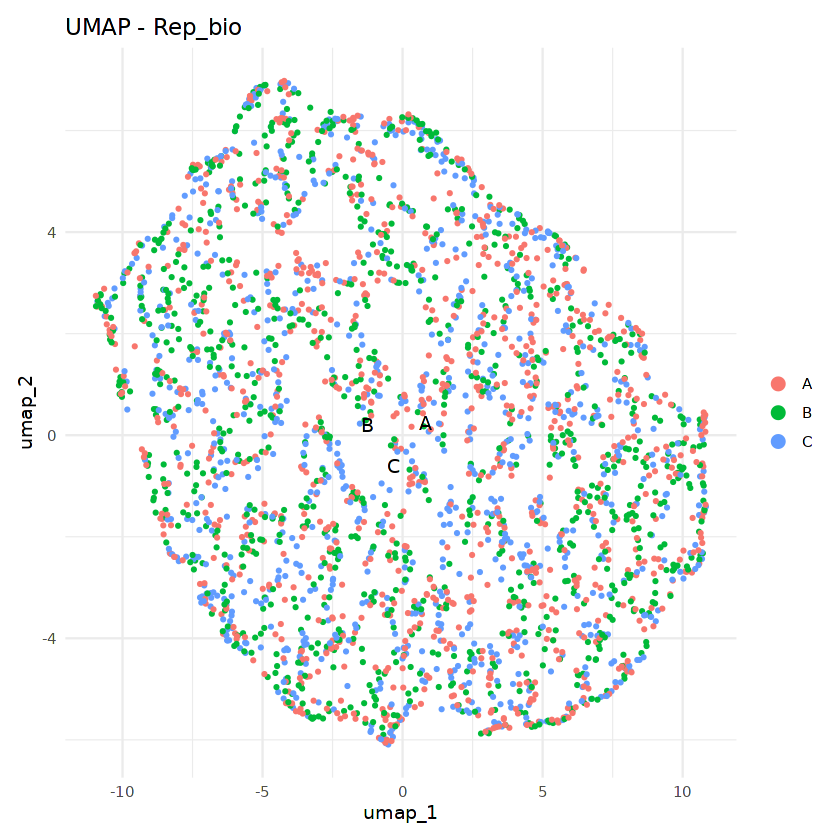

In [68]:
DimPlot(seurat_object, reduction = "umap", group.by = "Rep_bio", label = TRUE, repel = TRUE) +
    ggtitle("UMAP - Rep_bio") +
    theme_minimal()

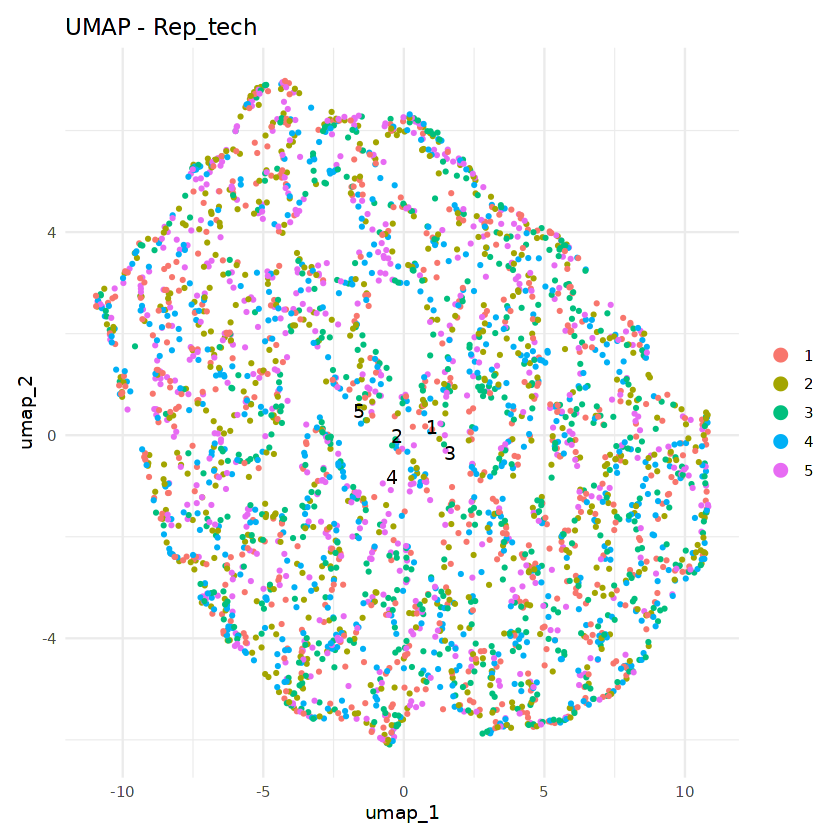

In [69]:
DimPlot(seurat_object, reduction = "umap", group.by = "Rep_tech", label = TRUE, repel = TRUE) +
    ggtitle("UMAP - Rep_tech") +
    theme_minimal()

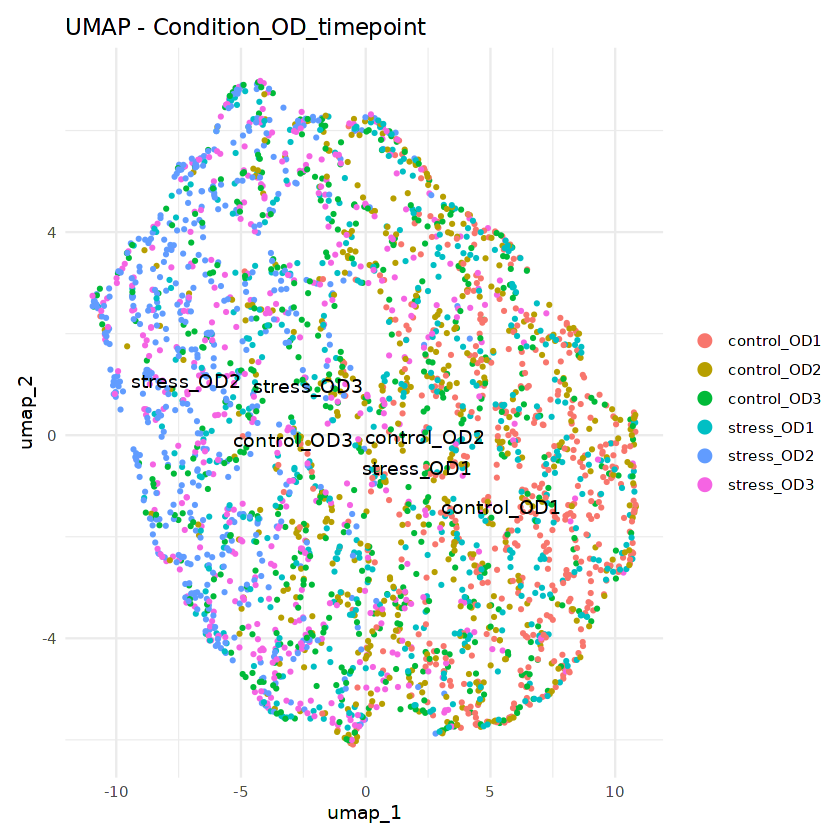

In [70]:
DimPlot(seurat_object, reduction = "umap", group.by = "Condition_OD_timepoint", label = TRUE, repel = TRUE) +
    ggtitle("UMAP - Condition_OD_timepoint") +
    theme_minimal()

In [71]:

At this point in the analysis, particularly with larger datasets you might want to save you data. Just incase your computer crashes or if you forget to save your progress! An amazing feature in R, is that you can always save your Seurat Object. This is really useful for collaboration and sharing the data as well. To do this you can use the following command: `saveRDS(seurat_object, file = 'seurat_object.rds')`


ERROR: Error in parse(text = input): <text>:2:4: unexpected symbol
1: 
2: At this
      ^


## Step 10: Finding marker genes and differential expression
Seurat can help you find markers (cluster/cell markers) that define clusters via differential expression. By default, it identifies positive and negative markers of a single cluster (specified in ident.1), compared to all other cells. `FindAllMarkers()` automates this process for all clusters, but you can also test groups of clusters vs. each other, or against all cells.

To find markers for every cluster compared to all remaining cells, and report only the positive ones you can use the below command. 
*Note: This takes a little while to calculate, and will vary depending on the number of clusters you have.*

In [ ]:
seurat_markers <- FindAllMarkers(seurat_object, only.pos = TRUE, min.pct = 0.25, logfc.threshold = 0.25)

Calculating cluster 0

For a (much!) faster implementation of the Wilcoxon Rank Sum Test,
(default method for FindMarkers) please install the presto package
--------------------------------------------
install.packages('devtools')
devtools::install_github('immunogenomics/presto')
--------------------------------------------
After installation of presto, Seurat will automatically use the more 
efficient implementation (no further action necessary).
This message will be shown once per session

Calculating cluster 1

Calculating cluster 2

Calculating cluster 3

Calculating cluster 4

Calculating cluster 5

Calculating cluster 6



Next we can extract the highest genes per cluster by their average log fold change (`avg_log2FC` in the data frame). You don't need to pay too much attention on the numbers themselves for the purposes of our project, but ultimately the p value (or corrected q-value!) describes how significantly different the expression of that gene is in the cluster compared to the other clusters (ie. higher PC value, the more statistically significant the difference). And the FC describes how different the expression level is between a gene in one cluster compared to the others.

***Tip**: you need to have loaded library(dplyr) to run the below but you have already imported this package at the start of the tutorial* 

The `%>%` is a magical operator in R which allows us to put lots of functions together. We are using it here to try and make the code a bit easier to follow.

In [ ]:
top_2_markers <- seurat_markers %>%
  group_by(cluster) %>%
  slice_max(n = 2, order_by = avg_log2FC)
top_2_markers

p_val,avg_log2FC,pct.1,pct.2,p_val_adj,cluster,gene
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>
2.115407e-45,0.6972658,0.292,0.075,9.400868e-42,0,QLH64-13700
1.699961e-37,0.6781034,0.251,0.067,7.554628e-34,0,QLH64-22670
1.838433e-12,1.0692911,0.268,0.152,8.169994e-09,1,QLH64-12160
1.247025e-09,0.5978673,0.384,0.273,5.541779e-06,1,QLH64-04480
1.118126e-03,0.4564853,0.160,0.260,1.000000e+00,2,QLH64-21010
5.160378e-05,0.3796207,0.146,0.262,2.293272e-01,2,QLH64-18290
2.179315e-04,1.0760414,0.119,0.261,9.684874e-01,5,QLH64-29870
3.954351e-04,0.8566151,0.167,0.337,1.000000e+00,5,QLH64-10165


In [ ]:
Below is an example if we wanted to find the differentially expressed genes between two cluster of interest. In this example we are looking at our cluster 0 and cluster 2. As you can see from the UMAP above, they are next to each other, which could suggest that they have similar transcriptomic profiles. Using `FindMarkers` we can investigate further into why they were put into different clusters.

In [ ]:
cluster_0_vs_cluster_2 <- FindMarkers(seurat_object, ident.1 = 0, ident.2 = 2, min.pct = 0.25)
head(cluster_0_vs_cluster_2, n=5)

,p_val,avg_log2FC,pct.1,pct.2,p_val_adj
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
QLH64-23145,1.462330e-30,0.4121831,0.455,0.097,6.498597e-27
QLH64-00400,2.905757e-30,0.4077081,0.473,0.107,1.291318e-26
QLH64-09295,1.992094e-29,0.3667852,0.542,0.146,8.852865e-26
QLH64-21125,6.139725e-29,0.3635256,0.515,0.131,2.728494e-25
QLH64-13700,2.421111e-28,1.7479134,0.292,0.031,1.075942e-24


If we wanted to compare between 2 clusters, we would need to specify the `idents`. e.g. `ident.1 = 3, ident.2 = 7`. You can also compare one ident vs many by combining serval different idents/metadata field into a list e.g. `ident.1 = 3, ident.2 = c(7, 8)`

## Step 11: Assigning cell type

We can then start exploring the expression of these markers using:
- `DoHeatmap()`
- `VlnPlot()`
- `FeaturePlot()`
- `DotPlot()`

**To do**: A great way to initially visualize the top markers for all clusters is through a heatmap. This might not look perfectly polished but its a good starting point to compare all the top markers across your clusters.

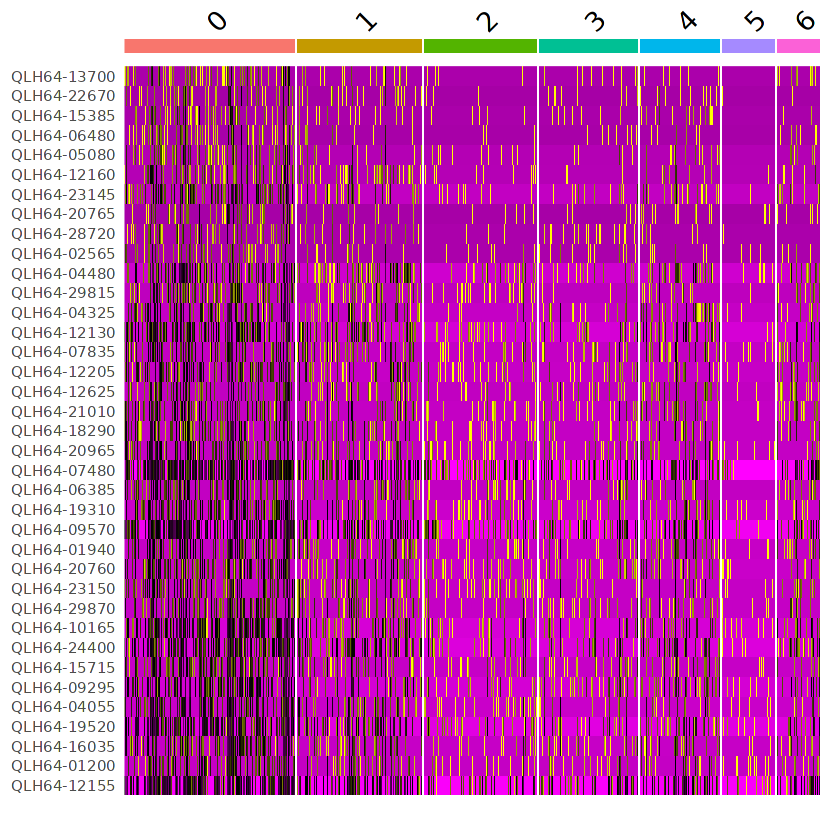

In [ ]:
top_10_markers <- seurat_markers %>%
  group_by(cluster) %>%
  slice_max(n = 10, order_by = avg_log2FC)
DoHeatmap(seurat_object, features = top_10_markers$gene) + NoLegend()

#analysis 

##parameters that we can use 
# scale.factor = 10000
# nfeatures = 2000

#for the graph we can change top number 


#don't change :
# normalization.method = "LogNormalize"
# selection.method = "vst"
#


In [ ]:
# Exploring variable features
top10 <- head(VariableFeatures(seurat_object), n=10)
top10

[1] "QLH64-16410" "QLH64-23490" "QLH64-25115" "QLH64-12320" "QLH64-24590"
 [6] "QLH64-08635" "QLH64-22445" "QLH64-28020" "QLH64-19950" "QLH64-25710"

Normalizing layer: counts

Finding variable features for layer counts



[1] "QLH64-16410" "QLH64-23490" "QLH64-25115" "QLH64-12320" "QLH64-24590"
 [6] "QLH64-08635" "QLH64-22445" "QLH64-28020" "QLH64-19950" "QLH64-25710"

When using repel, set xnudge and ynudge to 0 for optimal results



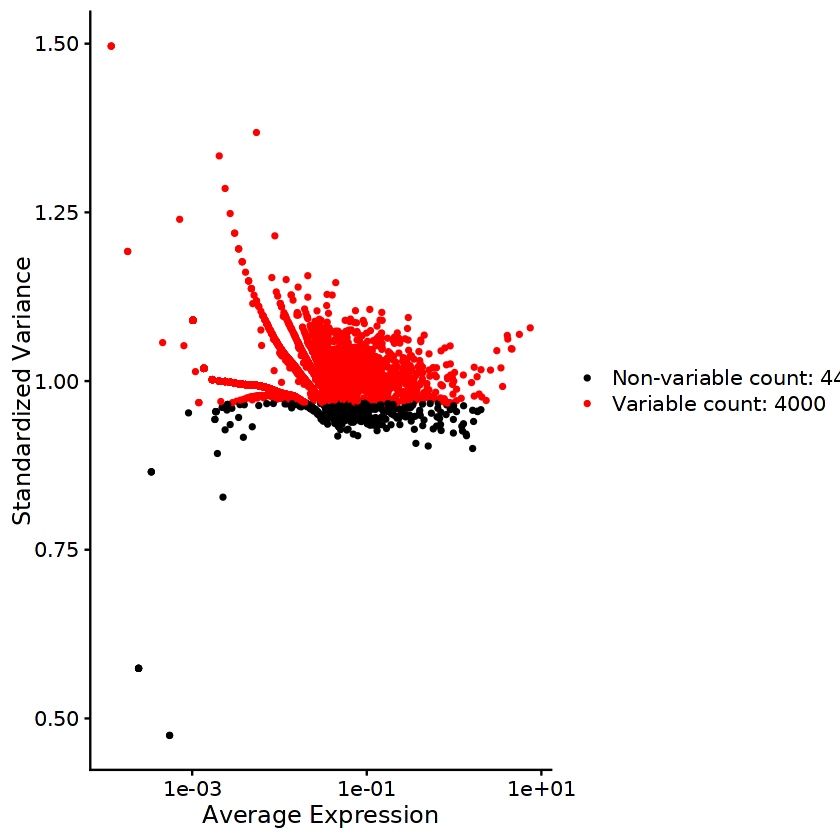

Centering and scaling data matrix

PC_ 1 
Positive:  QLH64-07515, QLH64-27715, QLH64-11275, QLH64-10225, QLH64-02615, QLH64-26985, QLH64-19625, QLH64-02320, QLH64-01365, QLH64-25105 
	   QLH64-20710, QLH64-19620, QLH64-03265, QLH64-21740, QLH64-25685, QLH64-28305, QLH64-05945, QLH64-23410, QLH64-22235, QLH64-20920 
	   QLH64-17200, QLH64-14575, QLH64-18875, QLH64-24600, QLH64-30225, QLH64-00115, QLH64-17150, QLH64-07010, QLH64-12430, QLH64-07995 
Negative:  QLH64-00420, QLH64-05310, QLH64-07480, QLH64-16050, QLH64-13725, QLH64-26960, QLH64-03465, QLH64-12435, QLH64-17465, QLH64-12125 
	   QLH64-27050, QLH64-27060, QLH64-23140, QLH64-29825, QLH64-12150, QLH64-22540, QLH64-21575, QLH64-30060, QLH64-09580, QLH64-25495 
	   QLH64-08920, QLH64-20660, QLH64-09570, QLH64-02835, QLH64-13715, QLH64-13730, QLH64-00840, QLH64-09590, QLH64-02935, QLH64-00430 
PC_ 2 
Positive:  QLH64-04245, QLH64-19980, QLH64-24460, QLH64-18560, QLH64-28630, QLH64-17885, QLH64-04085, QLH64-03820, QLH64-30940, QLH64

An object of class Seurat 
4444 features across 2937 samples within 1 assay 
Active assay: RNA (4444 features, 4000 variable features)
 3 layers present: counts, data, scale.data
 2 dimensional reductions calculated: pca, umap

PC_ 1 
Positive:  QLH64-07515, QLH64-27715, QLH64-11275, QLH64-10225, QLH64-02615, QLH64-26985, QLH64-19625, QLH64-02320, QLH64-01365, QLH64-25105 
Negative:  QLH64-00420, QLH64-05310, QLH64-07480, QLH64-16050, QLH64-13725, QLH64-26960, QLH64-03465, QLH64-12435, QLH64-17465, QLH64-12125 
PC_ 2 
Positive:  QLH64-04245, QLH64-19980, QLH64-24460, QLH64-18560, QLH64-28630, QLH64-17885, QLH64-04085, QLH64-03820, QLH64-30940, QLH64-24010 
Negative:  QLH64-28325, QLH64-29000, QLH64-23445, QLH64-15220, QLH64-27410, QLH64-19885, QLH64-03745, QLH64-12425, QLH64-20900, QLH64-29960 
PC_ 3 
Positive:  QLH64-28325, QLH64-18135, QLH64-13270, QLH64-26870, QLH64-21555, QLH64-25555, QLH64-18670, QLH64-21800, QLH64-16655, QLH64-24585 
Negative:  QLH64-30600, QLH64-11665, QLH64-05590, QLH64-25985, QLH64-01340, QLH64-19040, QLH64-28350, QLH64-21835, QLH64-26305, QLH64-10670 
PC_ 4 
Positive:  QLH64-12325, QLH64-05485, QLH64-19720, QLH64-26345, QLH64-22655, QLH64-11420, QLH64-07000, QLH64-20435, QLH64-27895

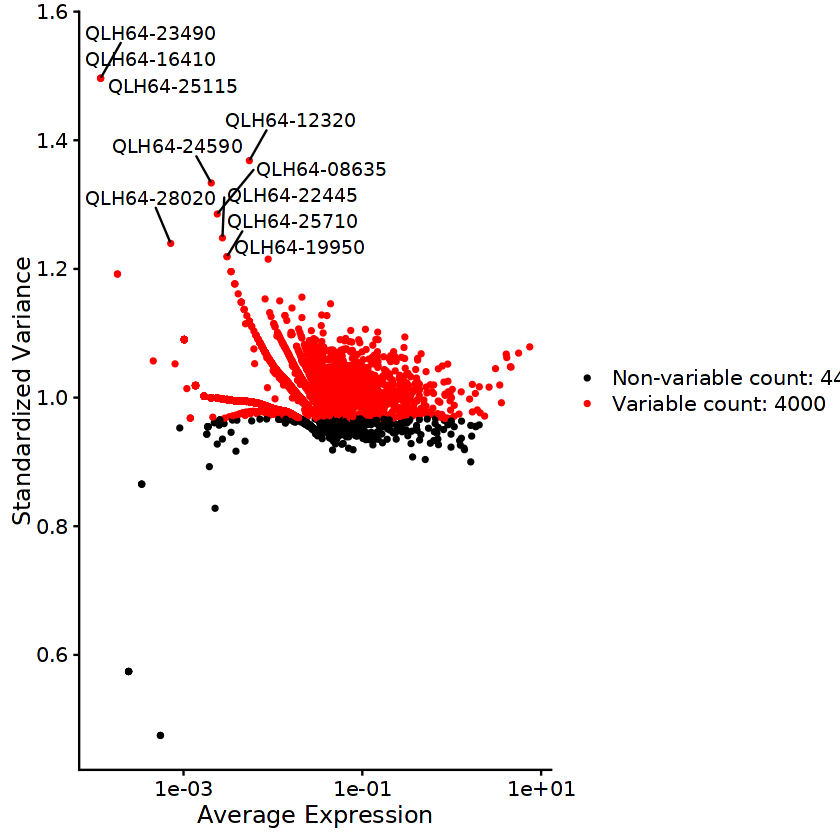

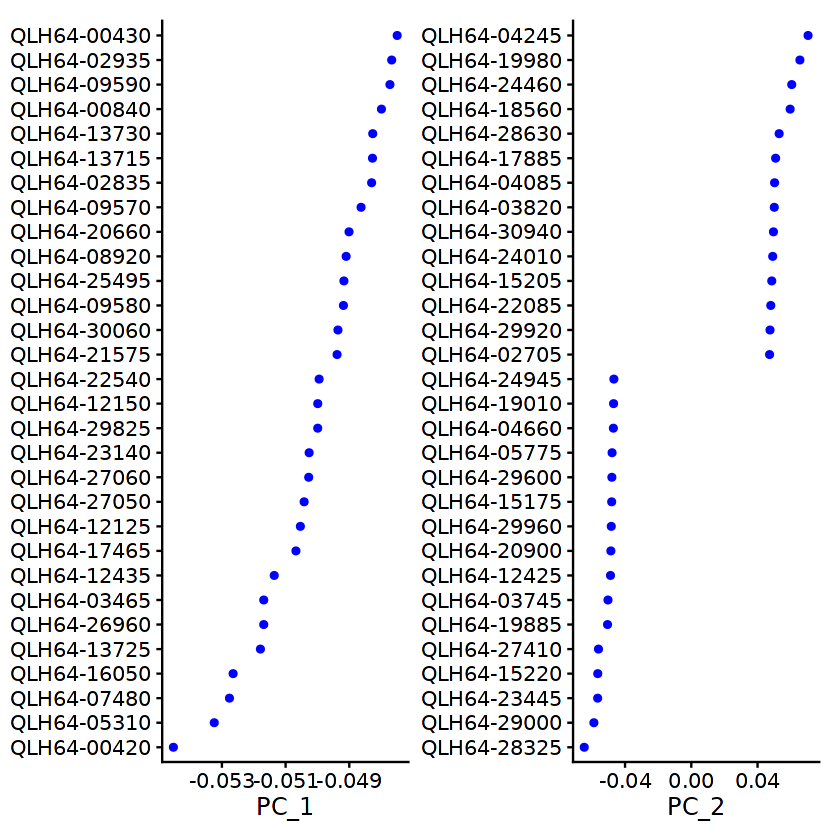

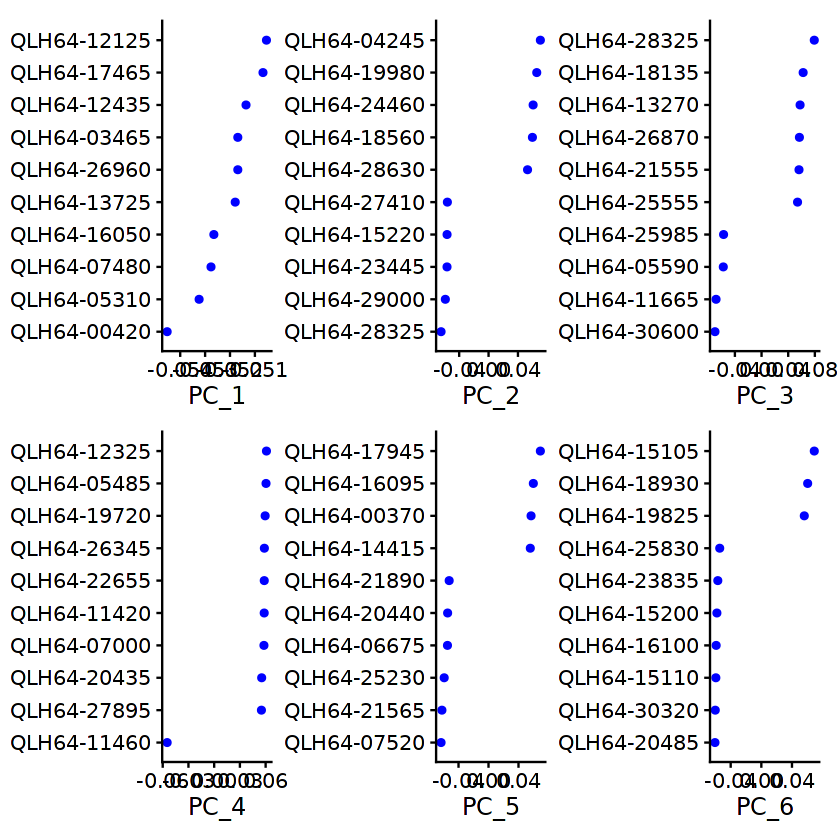

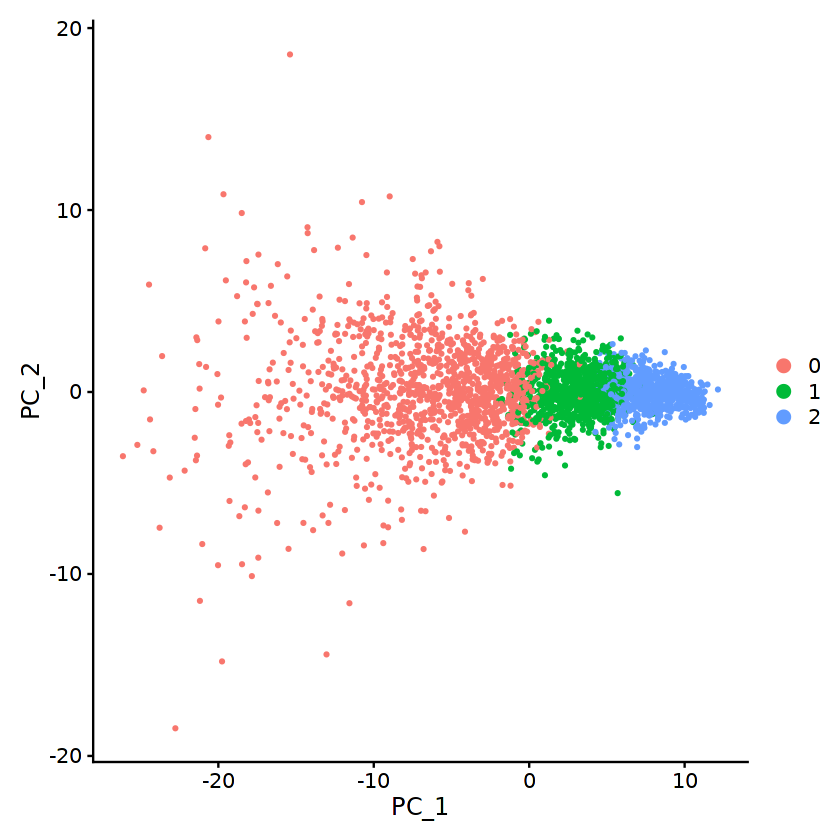

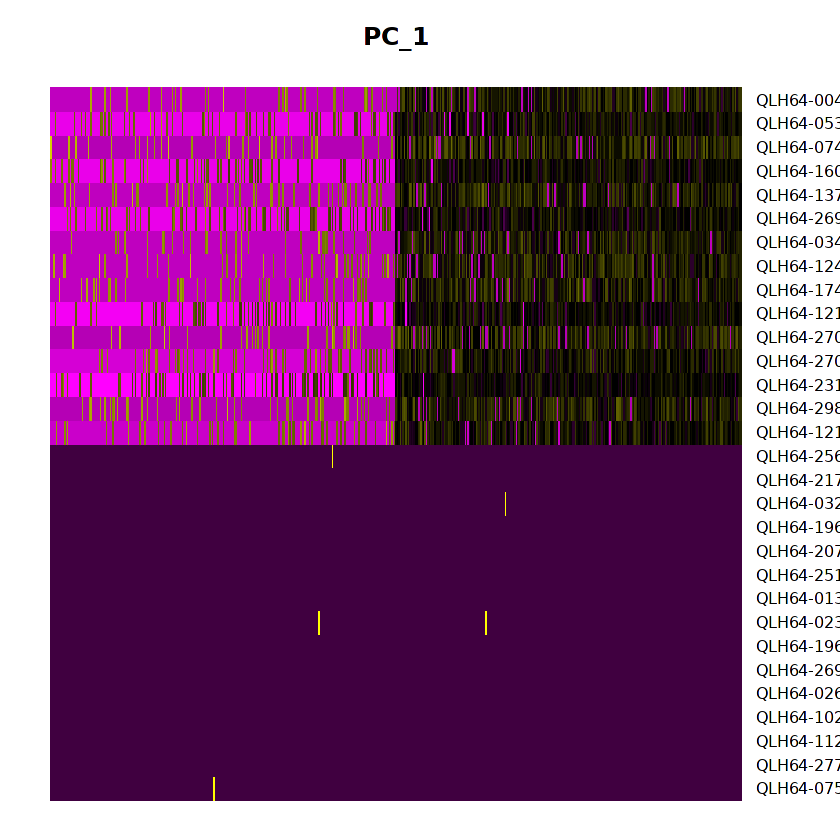

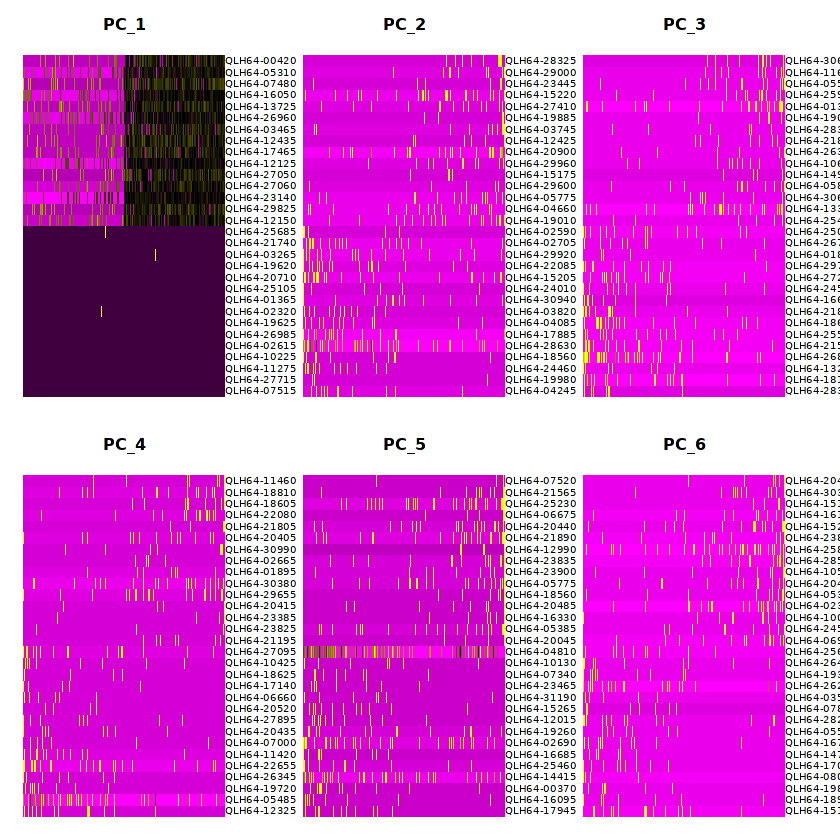

Computing nearest neighbor graph

Computing SNN



Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 2937
Number of edges: 100998

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.7665
Number of communities: 4
Elapsed time: 0 seconds


GTACGCAA_AACCGAGA_AAACGATA CGGATTGC_AACGCTTA_AAACGATA 
                         0                          0 
CGCTGATC_AACGTGAT_AAACGATA GCTAACGA_AAGAGATC_AAACGATA 
                         0                          1 
CCTCTATC_AAGGACAC_AAACGATA GTGTTCTA_ACACAGAA_AAACGATA 
                         0                          1 
ACAGATTC_ACAGATTC_AAACGATA CAAGACTA_ACATTGGC_AAACGATA 
                         0                          0 
CCGTGAGA_ACCACTGT_AAACGATA ACTATGCA_AGTACAAG_AAACGATA 
                         2                          0 
Levels: 0 1 2 3

12:08:10 UMAP embedding parameters a = 0.9922 b = 1.112

12:08:10 Read 2937 rows and found 10 numeric columns

12:08:10 Using Annoy for neighbor search, n_neighbors = 30

12:08:10 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

12:08:11 Writing NN index file to temp file /tmp/RtmpA2b7CE/file1841472d1dc6c

12:08:11 Searching Annoy index using 1 thread, search_k = 3000

12:08:12 Annoy recall = 100%

12:08:14 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 30

12:08:15 Initializing from normalized Laplacian + noise (using RSpectra)

12:08:15 Commencing optimization for 500 epochs, with 131552 positive edges

12:08:15 Using rng type: pcg

12:08:18 Optimization finished



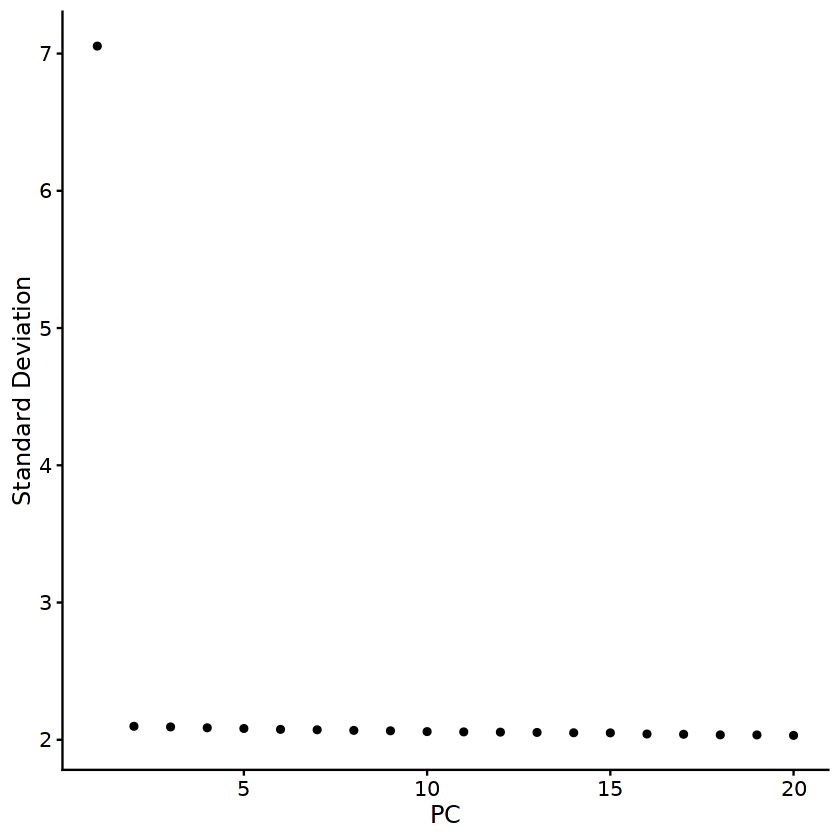

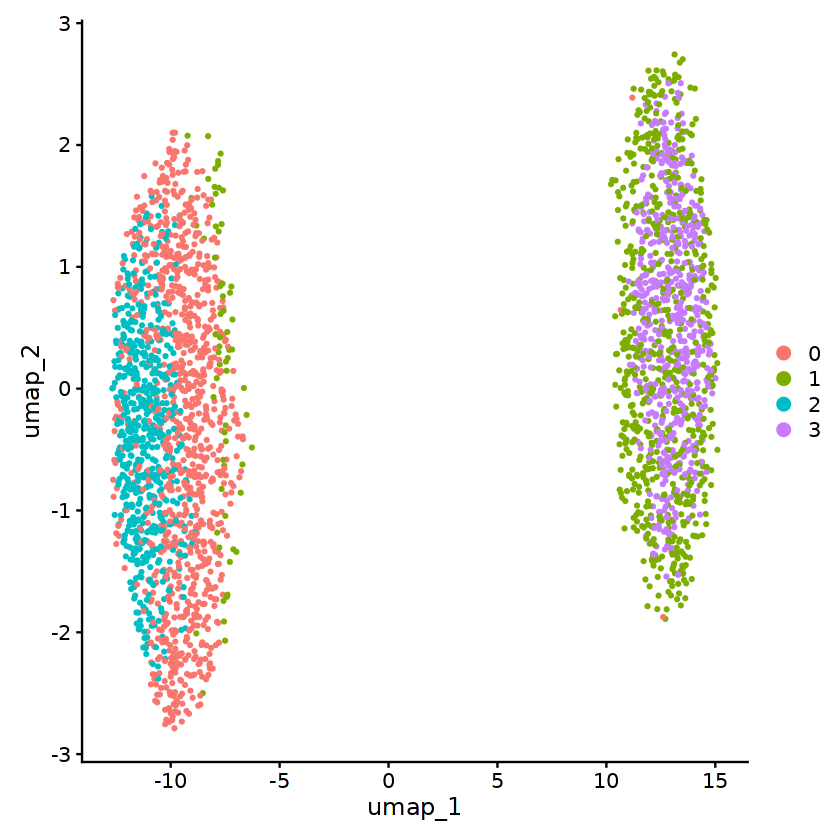

Calculating cluster 0

Calculating cluster 1

Calculating cluster 2

Calculating cluster 3



p_val,avg_log2FC,pct.1,pct.2,p_val_adj,cluster,gene
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>
3.561632e-03,0.3390875,0.185,0.273,1.000000e+00,0,QLH64-02920
9.896859e-06,0.2993939,0.150,0.254,4.398164e-02,0,QLH64-04845
3.884438e-09,0.3062838,0.285,0.191,1.726244e-05,1,QLH64-22135
1.833066e-09,0.2778235,0.291,0.193,8.146146e-06,1,QLH64-30065
1.338289e-16,0.4714051,0.095,0.289,5.947358e-13,2,QLH64-23150
3.225626e-19,0.4648055,0.129,0.373,1.433468e-15,2,QLH64-10165
2.136547e-42,0.6577886,0.259,0.058,9.494815e-39,3,QLH64-13890
1.880462e-48,0.5188795,0.323,0.077,8.356771e-45,3,QLH64-15385


,p_val,avg_log2FC,pct.1,pct.2,p_val_adj
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
QLH64-22540,4.337463e-10,0.2286248,0.394,0.183,1.927569e-06
QLH64-17465,5.302968e-10,0.1105219,0.412,0.193,2.356639e-06
QLH64-05310,8.212927e-10,0.1486930,0.557,0.283,3.649825e-06
QLH64-18925,9.369661e-10,0.1935225,0.280,0.119,4.163878e-06
QLH64-09570,1.489159e-09,0.2473402,0.317,0.142,6.617825e-06


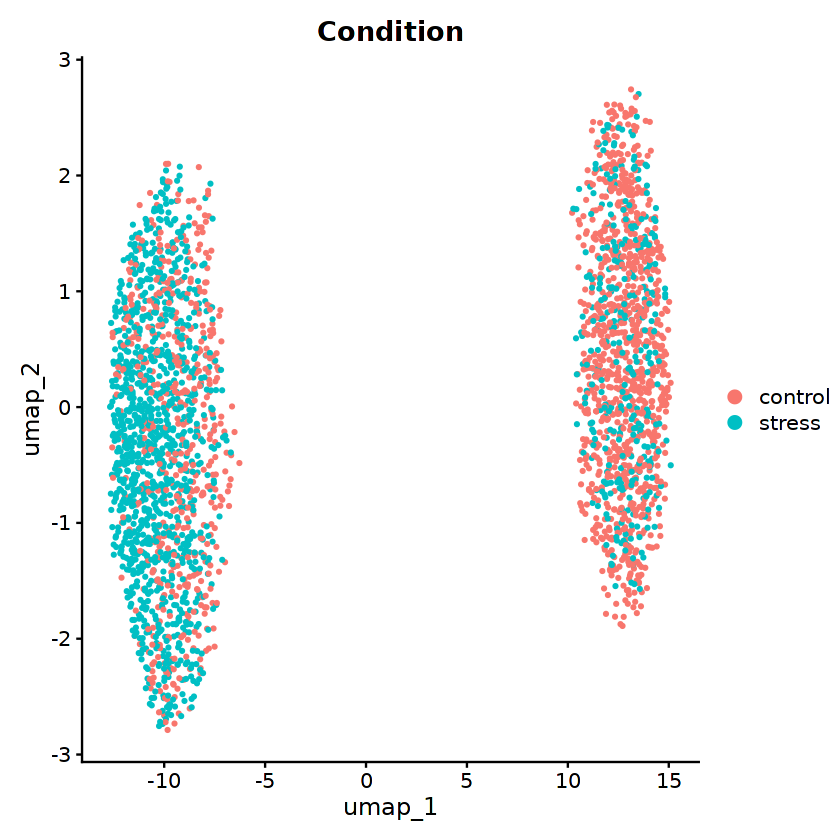

In [ ]:


#Normalisation
seurat_object <- NormalizeData(seurat_object, normalization.method = "LogNormalize", scale.factor = 10000)

#Find variable features
seurat_object <- FindVariableFeatures(seurat_object, selection.method = "vst", nfeatures = 4000)

# Exploring variable features
top10 <- head(VariableFeatures(seurat_object), n=10)
top10

var_feat_plot <- VariableFeaturePlot(seurat_object)
var_feat_plot

var_feat_plot_labeled <- LabelPoints(plot = var_feat_plot, points = top10, repel = TRUE)
var_feat_plot_labeled

# Scaling the data
all_genes <- rownames(seurat_object)
seurat_object <- ScaleData(seurat_object, features = all_genes)

# Running PCA
seurat_object <- RunPCA(seurat_object, features = VariableFeatures(object = seurat_object))
seurat_object

# Display PCA results
print(seurat_object[["pca"]], dims = 1:15, nfeatures = 10)

VizDimLoadings(seurat_object, dims = 1:2)
VizDimLoadings(seurat_object, dims = 1:6, reduction = "pca", ncol = 3, nfeature=10)
DimPlot(seurat_object, reduction = "pca", dims = 1:2)
DimHeatmap(seurat_object, dims = 1, cells = 500, balanced = TRUE)
DimHeatmap(seurat_object, dims = 1:6, cells = 500, balanced = TRUE, ncol = 3)
ElbowPlot(seurat_object)

#Clustering
seurat_object <- FindNeighbors(seurat_object, dims = 1:10)

seurat_object <- FindClusters(seurat_object, resolution = 0.5)

head(Idents(seurat_object), 10)
seurat_object <- RunUMAP(seurat_object, 1:10)

DimPlot(seurat_object, reduction = "umap")
DimPlot(seurat_object, reduction = "umap", group.by = "Condition")
seurat_markers <- FindAllMarkers(seurat_object, only.pos = TRUE, min.pct = 0.25, logfc.threshold = 0.25)

top_2_markers <- seurat_markers %>%
  group_by(cluster) %>%
  slice_max(n = 2, order_by = avg_log2FC)
top_2_markers


cluster_0_vs_cluster_2 <- FindMarkers(seurat_object, ident.1 = 0, ident.2 = 2, min.pct = 0.25)
head(cluster_0_vs_cluster_2, n=5)


Normalizing layer: counts

Normalizing layer: counts



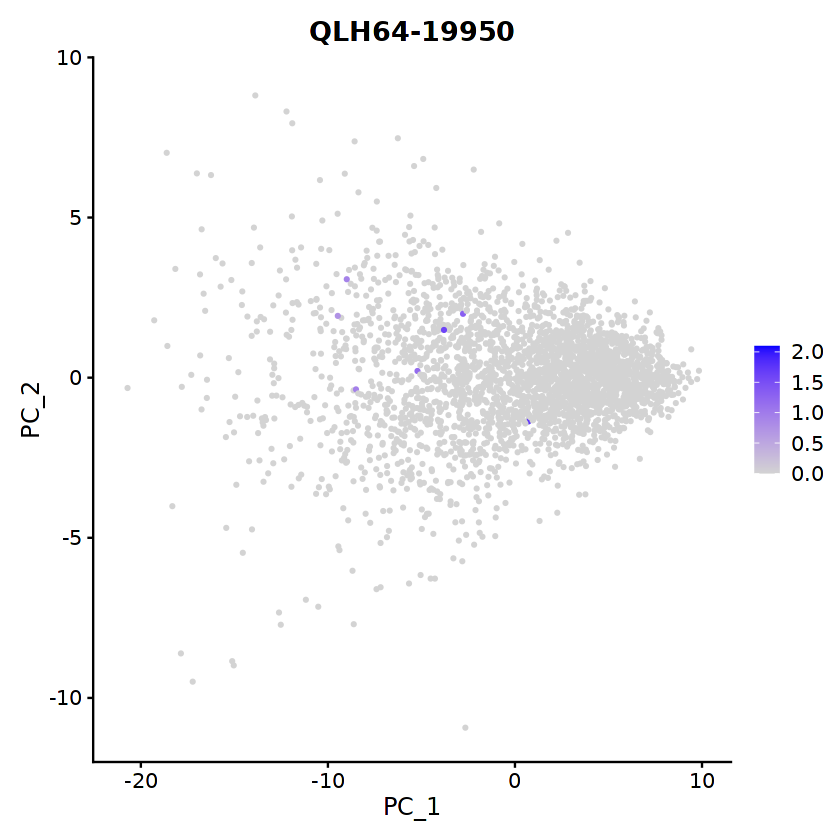

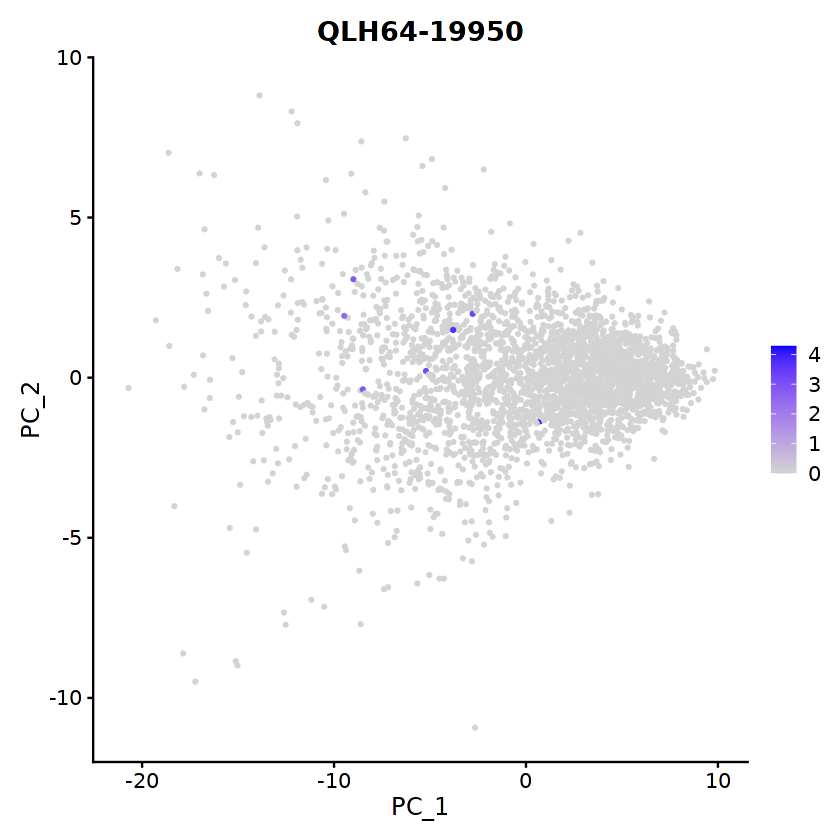

In [ ]:
# Compare two normalized versions
seurat_1000 <- NormalizeData(seurat_object, normalization.method = "LogNormalize", scale.factor = 1000)
seurat_10000 <- NormalizeData(seurat_object, normalization.method = "LogNormalize", scale.factor = 10000)

# Plot one gene across cells
FeaturePlot(seurat_1000, features = "QLH64-19950", reduction = "pca")
FeaturePlot(seurat_10000, features = "QLH64-19950", reduction = "pca")

Normalizing layer: counts



Normalizing layer: counts



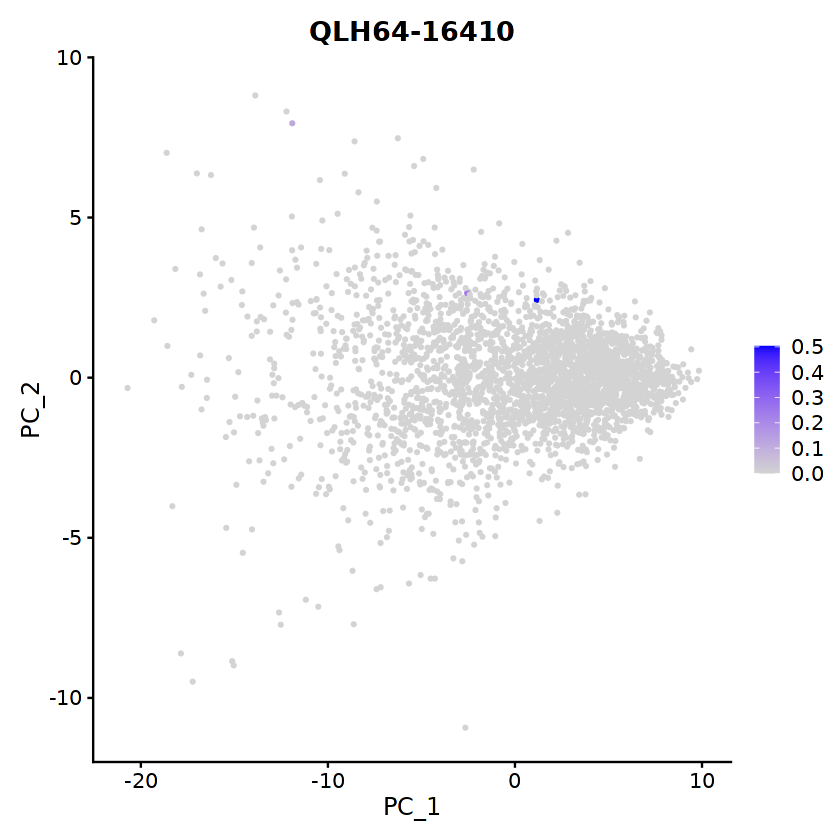

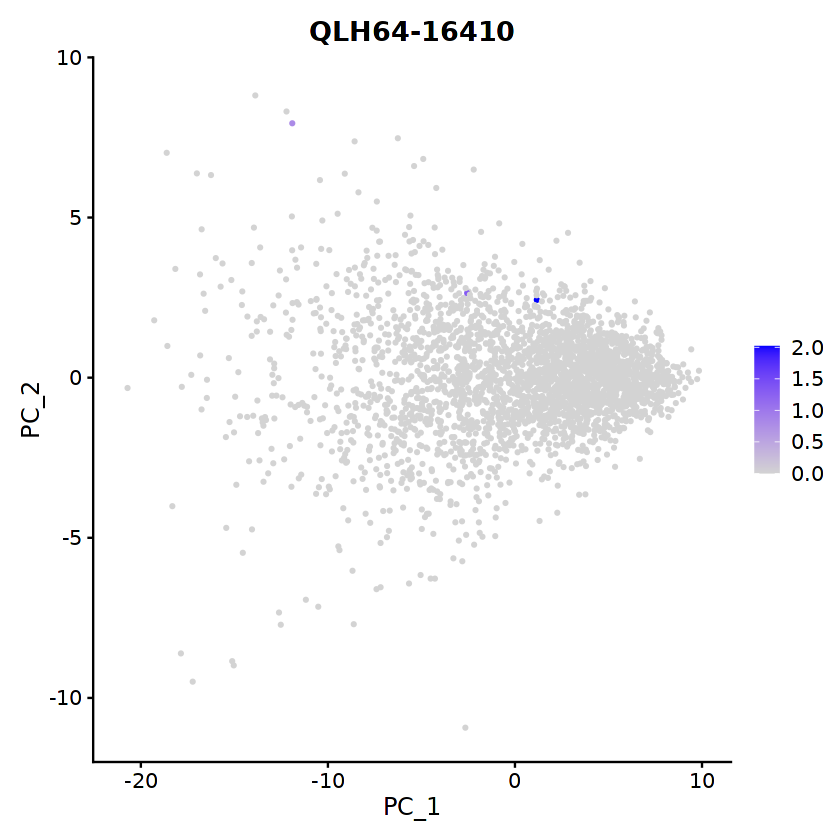

In [ ]:
# Compare two normalized versions
seurat_1000 <- NormalizeData(seurat_object, normalization.method = "LogNormalize", scale.factor = 1000)
seurat_10000 <- NormalizeData(seurat_object, normalization.method = "LogNormalize", scale.factor = 10000)

# Plot one gene across cells
FeaturePlot(seurat_1000, features = "QLH64-16410", reduction = "pca")
FeaturePlot(seurat_10000, features = "QLH64-16410", reduction = "pca")

In [ ]:
#